<a href="https://colab.research.google.com/github/JaimeEduardoC/18_Cardona_Buenaventura_Jaime/blob/main/Proyecto_de_programaci%C3%B3n_Deep_Vision_in_classification_tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07MIAR - Redes Neuronales y Deep Learning
## Proyecto de programación: *Deep Vision in classification tasks*
### Clasificación de imágenes de deportes

# **Integrantes del grupo:** *Santiago Lastra* - *Jaime Cardona*

**Objetivo.** Comparar experimentalmente dos estrategias para clasificar imágenes de 100 deportes:

1. Una red convolucional (CNN) diseñada y entrenada desde cero.
2. Arquitecturas preentrenadas en ImageNet, adaptadas mediante transfer learning y fine-tuning.

El notebook sigue el pipeline visto en clase: carga del dataset → inspección y análisis → preprocesamiento → diseño y entrenamiento → monitorización y toma de decisiones → evaluación y análisis de resultados.

# 0. Configuración del entorno

Se fija una semilla global y se conecta a Google Drive para poder guardar historiales de entrenamiento y modelos

In [ ]:
!pip install -q --upgrade kaggle

In [ ]:
from pathlib import Path

CARPETA_PROYECTO = Path("/content/drive/MyDrive/Redes_Neuronales")

if CARPETA_PROYECTO.exists():
    # Entorno local (Docker): la carpeta de Windows ya está montada en esta ruta
    print("Entorno local: carpeta del proyecto disponible en", CARPETA_PROYECTO)
else:
    # Colab en la nube: montamos Google Drive
    from google.colab import drive
    drive.mount("/content/drive")

print("¿Está kaggle.json?", (CARPETA_PROYECTO / "kaggle.json").exists())

Mounted at /content/drive
¿Está kaggle.json? True


In [ ]:
KAGGLE_JSON = "/content/drive/MyDrive/Redes_Neuronales/kaggle.json"

!mkdir -p ~/.kaggle
!cp "{KAGGLE_JSON}" ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
from pathlib import Path

BASE_FOLDER = "/content/drive/MyDrive/Redes_Neuronales/"
RESULTS_DIR = Path(BASE_FOLDER) / "resultados"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Los resultados se guardarán en:", RESULTS_DIR)

Los resultados se guardarán en: /content/drive/MyDrive/Redes_Neuronales/resultados


# 1. Selección, carga e inspección del dataset

## 1.1 Dataset elegido: *100 Sports Image Classification*

- **Fuente:** Kaggle — https://www.kaggle.com/datasets/gpiosenka/sports-classification (autor: Gerald Piosenka, licencia CC0).
- **Contenido:** fotografías de 100 deportes diferentes. El dataset está compuesto por imágenes JPG de 224x224x3 y que se encuentran ya separadas en train, valid y test. Esto lo corroboraremos en las celdas posteriores.

**Justificación de la elección**

- Problema de clasificación bien definido ya que cada imagen corresponde a un único deporte.
- El dataset es de un tamaño bueno para entrenar redes profundas y una partición de test independiente, que no se usará hasta la evaluación final.
- Buen escenario para comparar las dos estrategias: con 100 clases y del orden de un centenar de imágenes por clase, una CNN desde cero dispone de pocos ejemplos por categoría y es propensa al sobreajuste. En cambio, ImageNet contiene categorías relacionadas con este dominio, por lo que es esperable que el transfer learning aporte mucho.
- Clases visualmente parecidas (football / rugby ; formula 1 racing / nascar racing) que permitirán analizar los errores más allá de la accuracy.

## 1.2 Descarga del dataset mediante la API de Kaggle


In [ ]:
import os, json, random, shutil, hashlib, zipfile, subprocess
from pathlib import Path

def descargar_dataset_kaggle(slug, destino):
    destino = Path(destino)
    if destino.exists() and any(destino.iterdir()):
        print(f"Dataset ya disponible en {destino} (no se descarga de nuevo).")
        return destino
    destino.mkdir(parents=True, exist_ok=True)
    res = subprocess.run(["kaggle", "datasets", "download", slug, "-p", str(destino)],
                         capture_output=True, text=True)
    if res.returncode != 0:
        raise RuntimeError("Error al descargar de Kaggle:\n" + res.stderr + res.stdout)
    for zip_path in destino.glob("*.zip"):
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(destino)
        zip_path.unlink()
    print("Descarga y descompresión completadas.")
    return destino

def buscar_carpeta(raiz, nombre):
    candidatas = sorted((p for p in Path(raiz).rglob(nombre) if p.is_dir()), key=lambda p: len(p.parts))
    if not candidatas:
        raise FileNotFoundError(f"No se encontró '{nombre}' en {raiz}")
    return candidatas[0]

DATA_DIR = descargar_dataset_kaggle("gpiosenka/sports-classification", "/content/sports")

print("\nContenido descargado:")
for p in sorted(DATA_DIR.iterdir()):
    tipo = "carpeta" if p.is_dir() else f"fichero ({p.stat().st_size / 1e6:.1f} MB)"
    print(f"  {p.name:<45} {tipo}")

SPLITS = {s: buscar_carpeta(DATA_DIR, s) for s in ["train", "valid", "test"]}
for s, ruta in SPLITS.items():
    print(f"{s:<6} -> {ruta}")

Descarga y descompresión completadas.

Contenido descargado:
  EfficientNetB0-100-(224 X 224)- 98.40.h5      fichero (76.2 MB)
  sports.csv                                    fichero (0.7 MB)
  test                                          carpeta
  train                                         carpeta
  valid                                         carpeta
train  -> /content/sports/train
valid  -> /content/sports/valid
test   -> /content/sports/test


## 1.3 Estructura: número de imágenes y de clases

In [ ]:
import numpy as np
import pandas as pd

#SE ESTUDIAN LAS EXTENSIONES DE LOS ARCHIVOS
TIPO_IMAGEN = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

def inventariar_imagenes(split, carpeta):
  filas = [{"ruta": str(f), "clase": d.name, "split": split, "ext": f.suffix.lower()}
           for d in sorted(carpeta.iterdir()) if d.is_dir()
           for f in sorted(d.iterdir()) if f.is_file()]
  return pd.DataFrame(filas)

df = pd.concat([inventariar_imagenes(s,c) for s,c in SPLITS.items()], ignore_index = True)

no_imagen = df[~df["ext"].isin(TIPO_IMAGEN)]
print(f"Cantidad de ficheros que no son imágenes: {len(no_imagen)}")

if len(no_imagen): #Si el archivo no tiene extensión de imágen o gif se elimina del dataframe
  display(no_imagen[["split", "clase", "ruta"]])
df = df[df["ext"].isin(TIPO_IMAGEN)].reset_index(drop=True)

#Se hace un resumen del dataframe
resumen = (df.groupby("split").agg(imagenes=("ruta", "size"), clases=("clase", "nunique"))
             .reindex(["train", "valid", "test"]))
resumen["% del total"] = (100 * resumen["imagenes"] / resumen["imagenes"].sum()).round(1)

print("\n\nLa cantidad de imágenes que hay por partición:")
display(resumen)
print("\nTotal de imágenes:", resumen["imagenes"].sum())

clases_split = {s: set(df.loc[df["split"] == s, "clase"]) for s in SPLITS}
CLASES = sorted(clases_split["train"])
N_CLASES = len(CLASES)
print("Número de clases:", N_CLASES)
print("Mismas clases en train, valid y test:",
      clases_split["train"] == clases_split["valid"] == clases_split["test"])



Cantidad de ficheros que no son imágenes: 1


,split,clase,ruta
5621,train,high jump,/content/sports/train/high jump/159.lnk




La cantidad de imágenes que hay por partición:


,imagenes,clases,% del total
split,,,
train,13492,100,93.1
valid,500,100,3.5
test,500,100,3.5



Total de imágenes: 14492
Número de clases: 100
Mismas clases en train, valid y test: True


Observaciones:
- El dataset contiene 14.492 imágenes repartidas en 100 clases, y los tres splits tienen exactamente las mismas clases.
- El reparto entre splits es muy desigual: train concentra el 93,1 % de las imágenes, y valid y test solo 500 imágenes cada uno (3,5 %).
- Con 500 imágenes de test, cada imagen equivale a 0,2 puntos de *accuracy* y el margen de error de la estimación (IC 95 %) es de unos ±2,6 puntos si la accuracy ronda el 90 % (±4,4 si ronda el 50 %). Diferencias menores entre modelos no deben considerarse concluyentes. Por el mismo motivo, la accuracy de validación oscilará entre épocas, lo que conviene tener en cuenta al usar early stopping.
- Se encontró un fichero que no es una imagen (`train/high jump/159.lnk`), que se excluye del análisis.

## 1.4 Dimensiones, formato e integridad de las imágenes

In [ ]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

# SE LE AGREGAN MAS COLUMNAS AL DATAFRAME
def analizar_imagen(ruta):
    try:
        with Image.open(ruta) as im:
            formato, modo, (ancho, alto) = im.format, im.mode, im.size
            im.load()
        return {"ancho": ancho, "alto": alto, "modo": modo, "formato": formato, "ok": True}
    except Exception:
        return {"ancho": None, "alto": None, "modo": None, "formato": None, "ok": False}

with ThreadPoolExecutor(max_workers=8) as ex:
    info = pd.DataFrame(list(ex.map(analizar_imagen, df["ruta"])))
df = df.drop(columns=info.columns, errors="ignore").join(info)
df[["ancho", "alto"]] = df[["ancho", "alto"]].astype("Int64")

#Resumen del dataframe
print("Dimensiones encontradas (ancho x alto):")
display(df.groupby(["ancho", "alto"]).size().rename("nº imágenes")
          .sort_values(ascending=False).to_frame())
print("Modos de color:", df["modo"].value_counts(dropna=False).to_dict())
print("Formatos reales:", df["formato"].value_counts(dropna=False).to_dict())

FORMATOS_TF = {"JPEG", "PNG", "BMP", "GIF"}
problemas = df[(~df["ok"]) | (~df["formato"].isin(FORMATOS_TF))]
print(f"\nImágenes corruptas o con formato no soportado por TensorFlow: {len(problemas)}")
if len(problemas):
    display(problemas[["split", "clase", "ruta", "formato"]])

Dimensiones encontradas (ancho x alto):


,,nº imágenes
ancho,alto,
224,224,14492


Modos de color: {'RGB': 14482, 'L': 10}
Formatos reales: {'JPEG': 14492}

Imágenes corruptas o con formato no soportado por TensorFlow: 0


**Observaciones:**

- Todas las imágenes tienen un tamaño de 224×224 píxeles, y esto es bueno ya que los modelos preentrenados trabajan con esa resolución. Para la CNN que se entrenará desde cero, se evaluará utilizar una resolución menor para reducir el tiempo de entrenamiento.
- 14.482 imágenes están en formato RGB y solo 10 están en escala de grises (modo "L"). Sin embargo, al cargarlas con `color_mode="rgb"`, Keras convierte automáticamente estas imágenes a tres canales, por lo que no es necesario realizar un tratamiento adicional.
- Todas las imágenes están en formato JPEG y no se encontraron archivos corruptos, así que no deberían presentarse problemas al momento de cargarlas durante el entrenamiento.

## 1.5 Imágenes duplicadas y posible fuga de información


In [ ]:
import hashlib

def md5(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

df["md5"] = [md5(r) for r in df["ruta"]]

repetidas = df[df.duplicated("md5", keep=False)]
print("Grupos de imágenes idénticas:", repetidas["md5"].nunique())

hash_eval = set(df.loc[df["split"] != "train", "md5"])
fuga = df[(df["split"] == "train") & df["md5"].isin(hash_eval)]
print("Imágenes de train que también están en valid/test (fuga):", len(fuga))

conflicto = repetidas.groupby("md5")["clase"].nunique()
print("Imágenes idénticas con etiquetas distintas:", int((conflicto > 1).sum()))
if len(fuga):
    display(fuga[["clase", "ruta"]].head(20))

Grupos de imágenes idénticas: 0
Imágenes de train que también están en valid/test (fuga): 0
Imágenes idénticas con etiquetas distintas: 0


**Observaciones:**
- No hay imágenes duplicadas, ni fuga de información, ni imágenes idénticas con etiquetas distintas.
- Limitación: el hash MD5 solo detecta copias exactas; no detectaría la misma fotografía recortada o recomprimida.
- Como no hay imágenes corruptas ni duplicadas, no es necesario descartar ninguna. El único fichero ajeno (`159.lnk`) es ignorado automáticamente por las funciones de carga de Keras, que solo leen extensiones de imagen.

## 1.6 Distribución de las clases


Imágenes por clase en TRAIN:
  media = 134.9 | desviación típica = 21.5
  mínimo = 59 (sky surfing) | máximo = 191 (football)
  ratio de desbalanceo (máx/mín) = 3.24

VALID -> {imágenes por clase: nº de clases}: {5: 100}
TEST  -> {imágenes por clase: nº de clases}: {5: 100}


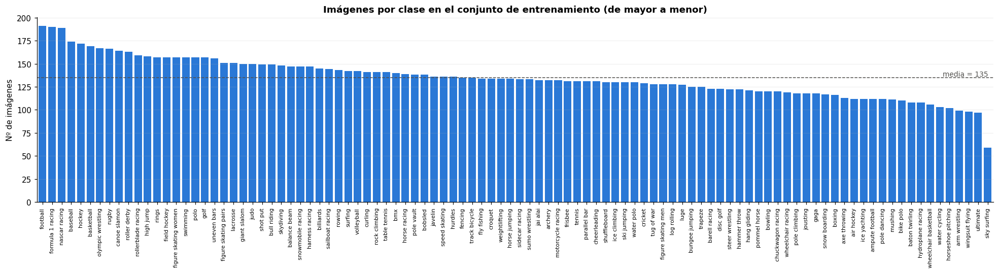

In [ ]:
import matplotlib.pyplot as plt

# Estilo común para las gráficas del notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titleweight": "bold",
})
COLOR = "#2a78d6"
COLOR_TEXTO = "#52514e"

conteo = (df.pivot_table(index="clase", columns="split", values="ruta",
                         aggfunc="count", fill_value=0)[["train", "valid", "test"]])
tr = conteo["train"]

print("Imágenes por clase en TRAIN:")
print(f"  media = {tr.mean():.1f} | desviación típica = {tr.std():.1f}")
print(f"  mínimo = {tr.min()} ({tr.idxmin()}) | máximo = {tr.max()} ({tr.idxmax()})")
print(f"  ratio de desbalanceo (máx/mín) = {tr.max() / tr.min():.2f}")
print("\nVALID -> {imágenes por clase: nº de clases}:", conteo["valid"].value_counts().to_dict())
print("TEST  -> {imágenes por clase: nº de clases}:", conteo["test"].value_counts().to_dict())

orden = tr.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(18, 5))
ax.bar(range(len(orden)), orden.values, color=COLOR, width=0.8)
ax.axhline(tr.mean(), color=COLOR_TEXTO, ls="--", lw=1)
ax.text(len(orden) - 0.5, tr.mean(), f"media = {tr.mean():.0f}  ", color=COLOR_TEXTO,
        ha="right", va="bottom", fontsize=9)
ax.set_xticks(range(len(orden)))
ax.set_xticklabels(orden.index, rotation=90, fontsize=7)
ax.set_xlim(-0.6, len(orden) - 0.4)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Nº de imágenes")
ax.set_title("Imágenes por clase en el conjunto de entrenamiento (de mayor a menor)")
plt.tight_layout()
plt.show()

**Observaciones:**
- En train hay una media de 134,9 imágenes por clase (desviación típica 21,5), con un mínimo de 59 (sky surfing) y un máximo de 191 (football). El ratio de desbalanceo es 3,24, pero se debe casi exclusivamente a "sky surfing"; la gran mayoría de clases está entre 100 y 175 imágenes.
- Valid y test están perfectamente balanceados: 5 imágenes por clase en las 100 clases. Por tanto, la accuracy es una métrica adecuada, ya que con un test balanceado coincide con el recall medio por clase.
- Por consecuencia no se aplicará `class_weight` de entrada. Se analizará el rendimiento por clase en la evaluación y, si las clases minoritarias (como sky surfing) obtienen resultados claramente peores, se probará como experimento adicional.
- Con solo 5 imágenes por clase en test, la accuracy de cada clase individual es muy ruidosa (cada imagen vale 20 puntos), por lo que el análisis por clase se interpretará con cautela.

## 1.7 Visualización de ejemplos

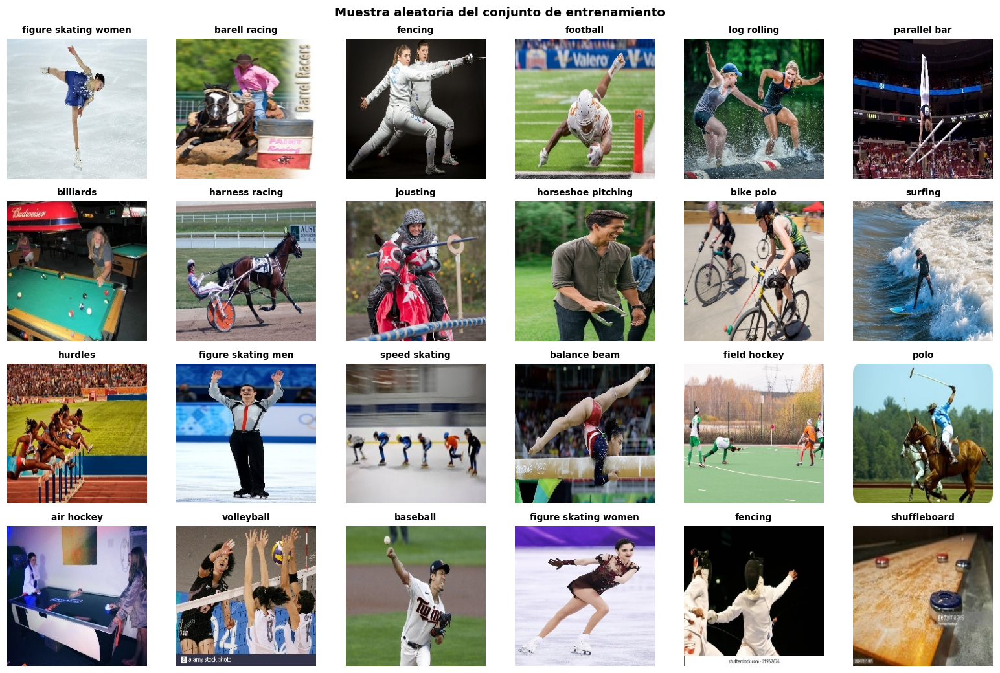

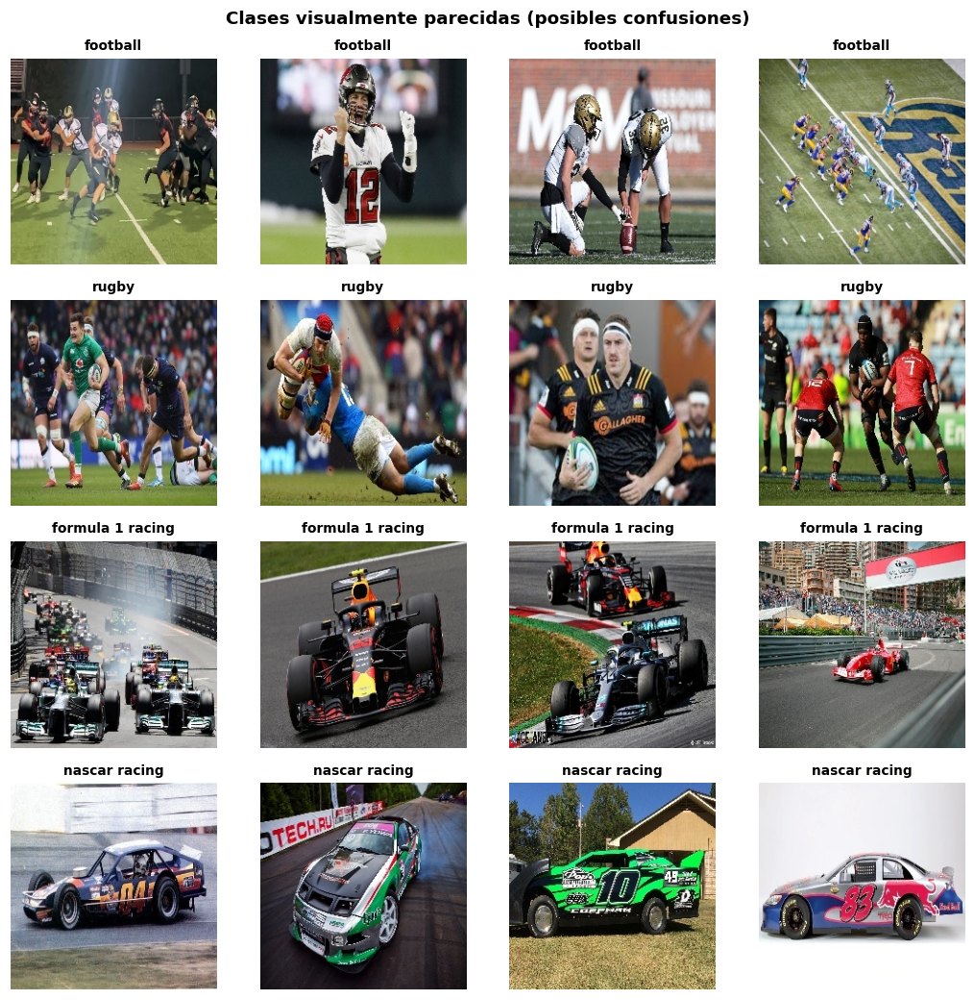

In [ ]:
SEED = 42

def mostrar_cuadricula(muestras, n_cols=6, tam=2.4, titulo=None):
    '''Muestra en cuadrícula las imágenes de un DataFrame con columnas 'ruta' y 'clase'.'''
    n_filas = int(np.ceil(len(muestras) / n_cols))
    fig, axes = plt.subplots(n_filas, n_cols, figsize=(n_cols * tam, n_filas * tam))
    axes = np.ravel(axes)
    for ax in axes:
        ax.axis("off")
    for ax, (_, fila) in zip(axes, muestras.iterrows()):
        ax.imshow(Image.open(fila["ruta"]).convert("RGB"))
        ax.set_title(fila["clase"], fontsize=9)
    if titulo:
        fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    plt.show()

train_df = df[df["split"] == "train"].copy()

mostrar_cuadricula(train_df.sample(24, random_state=SEED),
                   titulo="Muestra aleatoria del conjunto de entrenamiento")

parecidas = ["football", "rugby", "formula 1 racing", "nascar racing"]
muestras = pd.concat([train_df[train_df["clase"] == c].sample(4, random_state=SEED)
                      for c in parecidas])
print("\n")
mostrar_cuadricula(muestras, n_cols=4, titulo="Clases visualmente parecidas (posibles confusiones)")

## 1.8 Línea base: clasificadores triviales

In [ ]:
import json

clase_mayoritaria = tr.idxmax()
acc_aleatorio = 1 / N_CLASES
acc_mayoritario = conteo.loc[clase_mayoritaria, "test"] / conteo["test"].sum()

print(f"Clasificador aleatorio uniforme -> accuracy esperada en test = {acc_aleatorio:.2%}")
print(f"Siempre '{clase_mayoritaria}'   -> accuracy en test = {acc_mayoritario:.2%}")


with open(RESULTS_DIR / "dataset_info.json", "w") as f:
    json.dump({"clases": CLASES, "n_clases": N_CLASES,
               "acc_aleatorio": acc_aleatorio, "acc_mayoritario": float(acc_mayoritario),
               "imagenes_por_split": df["split"].value_counts().to_dict()}, f, indent=2)
print("Guardado en", RESULTS_DIR / "dataset_info.json")

Clasificador aleatorio uniforme -> accuracy esperada en test = 1.00%
Siempre 'football'   -> accuracy en test = 1.00%
Guardado en /content/drive/MyDrive/Redes_Neuronales/resultados/dataset_info.json


## 1.9 Análisis de nitidez (varianza del Laplaciano)

Con la varianza del Laplaciano se puede identificar qué tan nítida es una imagen, ya que si la varianza es alta significa que hay un cambio más notorio entre bordes y detalles pero si es baja significa que la imagen puede estar borrosa.

In [ ]:
import cv2

def calcular_blur(ruta):
    img = cv2.imread(ruta)

    if img is None:
        return np.nan

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()    # Se aplica el laplaciano y se calcula la varianza

train_df.loc[:, "laplacian_var"] = train_df["ruta"].apply(calcular_blur)

# Selección de las imágenes más borrosas (las que tienen una varianza laplaciana menor al 0.5%)
umbral_blur = train_df["laplacian_var"].quantile(0.005)

borrosas_df = train_df[(train_df["laplacian_var"] <= umbral_blur)].copy()

print("Umbral:", umbral_blur)
print("Imágenes borrosas:", len(borrosas_df))

Umbral: 130.08958318855503
Imágenes borrosas: 68


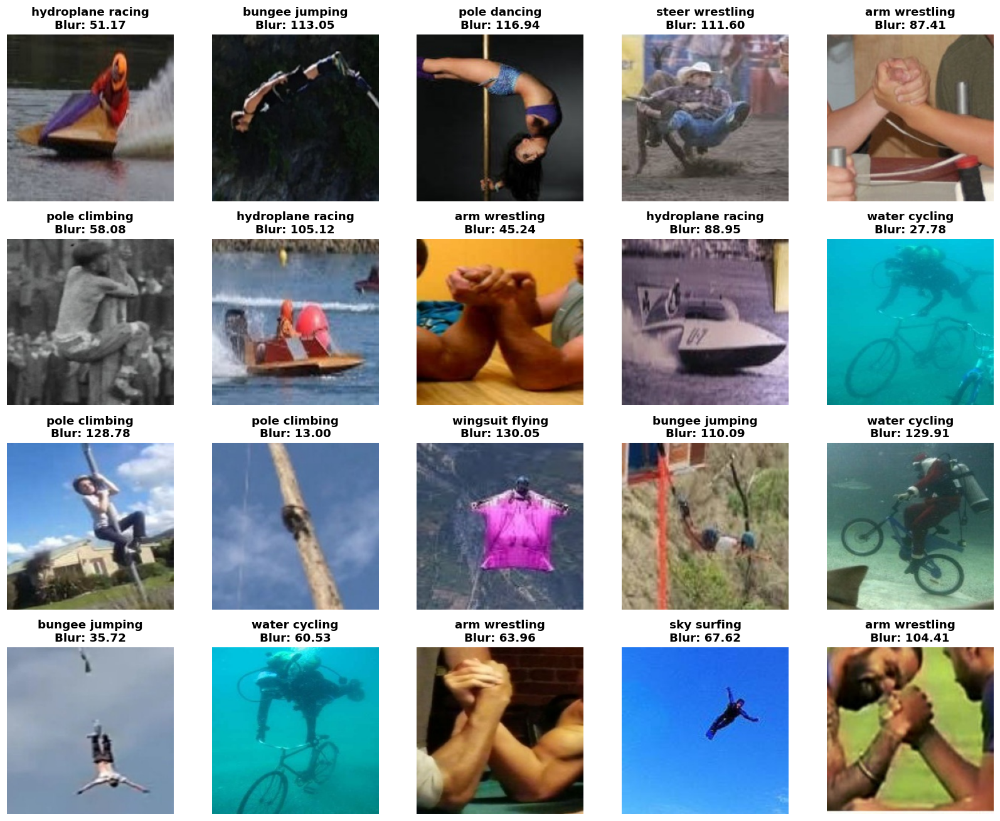

,baja varianza,total clase,% de la clase
clase,,,
water cycling,17,103,16.5
hydroplane racing,10,108,9.3
arm wrestling,9,99,9.1
pole climbing,7,118,5.9
wingsuit flying,7,98,7.1
pole dancing,6,112,5.4
baton twirling,3,108,2.8
bungee jumping,3,125,2.4
sky surfing,2,59,3.4


In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = np.ravel(axes)

for ax, (_, row) in zip(axes, borrosas_df.sample(20).iterrows()):

    ax.imshow(Image.open(row["ruta"]).convert("RGB"))
    ax.set_title(f'{row["clase"]}\nBlur: {row["laplacian_var"]:.2f}')
    ax.axis("off")

plt.tight_layout()
plt.show()

resumen_blur = (borrosas_df["clase"].value_counts().to_frame("baja varianza")
                .join(train_df["clase"].value_counts().rename("total clase")))
resumen_blur["% de la clase"] = (100 * resumen_blur["baja varianza"] / resumen_blur["total clase"]).round(1)
display(resumen_blur.head(10))

**Observaciones:** las imágenes con menor varianza del Laplaciano no son imágenes defectuosas, sino imágenes con poca textura por naturaleza: fotos bajo el agua (water cycling), primeros planos de piel (arm wrestling) o fondos de cielo (sky surfing, wingsuit flying). Todas siguen siendo reconocibles. Además, se concentran en pocas clases (ver tabla), por lo que eliminarlas quitaría precisamente los ejemplos más característicos de esas clases y reduciría aún más sky surfing, la clase minoritaria.

Por lo tanto se conservan todas las imágenes.

## 1.10 Conclusiones del análisis del dataset

La data al final es entonces:
- **Tamaño:** 14.492 imágenes (train 13.492, valid 500, test 500) repartidas en **100 clases**, las mismas en los tres splits.
- **Distribución:** en train, entre 59 (*sky surfing*) y 191 (*football*) imágenes por clase, con una media de 134,9. Desbalanceo moderado, concentrado en *sky surfing*. Valid y test están perfectamente balanceados (5 imágenes por clase), por lo que la accuracy es una métrica adecuada.
- **Dimensiones y formato:** todas las imágenes son JPEG de 224×224; 10 están en escala de grises y se convertirán a 3 canales al cargarlas.
- **Calidad:** ninguna imagen corrupta, ningún duplicado y ninguna fuga de información entre train y test. Solo se encontró un fichero ajeno (`.lnk`), que Keras ignora. La varianza del Laplaciano señaló 68 imágenes con poca textura (bajo el agua, cielo, primeros planos), concentradas en pocas clases; se conservaron por ser representativas.
- **Línea base:** tanto un clasificador aleatorio como uno que predice siempre la clase mayoritaria obtendrían un **1 %** de accuracy en test.
- **Implicaciones:** con unas 135 imágenes por clase, la CNN desde cero tiene alto riesgo de sobreajuste, por lo que la regularización y el data augmentation serán claves. Además, con solo 500 imágenes de test, diferencias de 1-2 puntos entre modelos no serán significativas.

# 2. Acondicionamiento y preprocesamiento de los datos

## 2.1 Parámetros generales

In [ ]:
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE_SCRATCH = 128
IMG_SIZE_TL = 224
BATCH_SIZE = 64
SHUFFLE_BUFFER = 4096

keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2.2 Pipeline de datos con `tf.data`

Se le hará un reescalado a la calidad de la imagen reduciendo los pixeles de 224x224 a 128x128 con el fin de reducir el costo computacional del entrenamiento.

In [ ]:
ds_prueba = keras.utils.image_dataset_from_directory(
    SPLITS["train"],
    labels="inferred",
    label_mode="int",
    class_names=CLASES,
    color_mode="rgb",
    image_size=(IMG_SIZE_SCRATCH, IMG_SIZE_SCRATCH),
    interpolation="area",
    batch_size=None,
    shuffle=True,
    seed=SEED,
)

Found 13492 files belonging to 100 classes.


Forma de la imagen : (128, 128, 3)
Tipo de número     : <dtype: 'float32'>
Valor mín. y máx.  : 2.6122448 255.0
Etiqueta (número)  : 26
Etiqueta (deporte) : field hockey


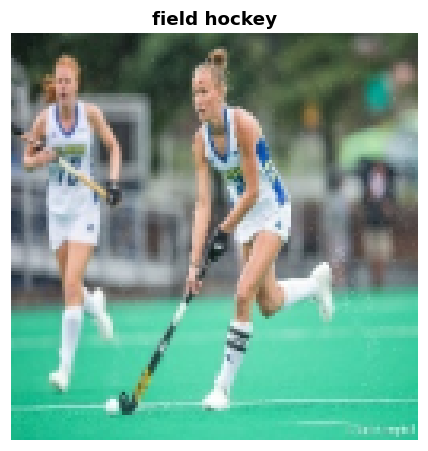

In [ ]:
imagen, etiqueta = next(iter(ds_prueba))

print("Forma de la imagen :", imagen.shape)
print("Tipo de número     :", imagen.dtype)
print("Valor mín. y máx.  :", imagen.numpy().min(), imagen.numpy().max())
print("Etiqueta (número)  :", int(etiqueta))
print("Etiqueta (deporte) :", CLASES[int(etiqueta)])

plt.imshow(imagen.numpy().astype("uint8"))
plt.title(CLASES[int(etiqueta)])
plt.axis("off")
plt.show()

Como se puede observar las imágenes ya tienen un tamaño de 128x128 píxeles y además cada una de las 100 etiquetas tiene ya asignado un número entero

In [ ]:
#SE CREA EL PIPELINE
def crear_datasets(img_size, batch_size=BATCH_SIZE):

    def cargar(split, barajar):
        return keras.utils.image_dataset_from_directory(
            SPLITS[split], labels="inferred", label_mode="int",
            class_names=CLASES, color_mode="rgb",
            image_size=(img_size, img_size), interpolation="area",
            batch_size=None, shuffle=barajar, seed=SEED)

    def preparar(ds, entrenamiento):
        ds = ds.map(lambda x, y: (tf.cast(tf.round(x), tf.uint8), y),
                    num_parallel_calls=AUTOTUNE)
        ds = ds.cache()
        if entrenamiento:
            ds = ds.shuffle(SHUFFLE_BUFFER, seed=SEED,
                            reshuffle_each_iteration=True)
        ds = ds.batch(batch_size)
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y),
                    num_parallel_calls=AUTOTUNE)
        return ds.prefetch(AUTOTUNE)

    train = preparar(cargar("train", barajar=True),  entrenamiento=True)
    valid = preparar(cargar("valid", barajar=False), entrenamiento=False)
    test  = preparar(cargar("test",  barajar=False), entrenamiento=False)
    return train, valid, test


train_ds, val_ds, test_ds = crear_datasets(IMG_SIZE_SCRATCH)
for nombre, ds in [("train", train_ds), ("valid", val_ds), ("test", test_ds)]:
    print(f"{nombre:<6}: {ds.cardinality().numpy()} paquetes")

Found 13492 files belonging to 100 classes.
Found 500 files belonging to 100 classes.
Found 500 files belonging to 100 classes.
train : 211 paquetes
valid : 8 paquetes
test  : 8 paquetes


**Resultados del pipeline:**

El conjunto de entrenamiento cambia el orden de las imágenes en cada época gracias al barajado, mientras que los conjuntos de validación y prueba mantienen siempre el mismo orden. Esto permite comparar las predicciones con sus etiquetas correspondientes durante la evaluación.

Resultado final: train con 211 lotes, valid y test con 8 lotes cada uno.

## 2.3 Comprobación visual del pipeline

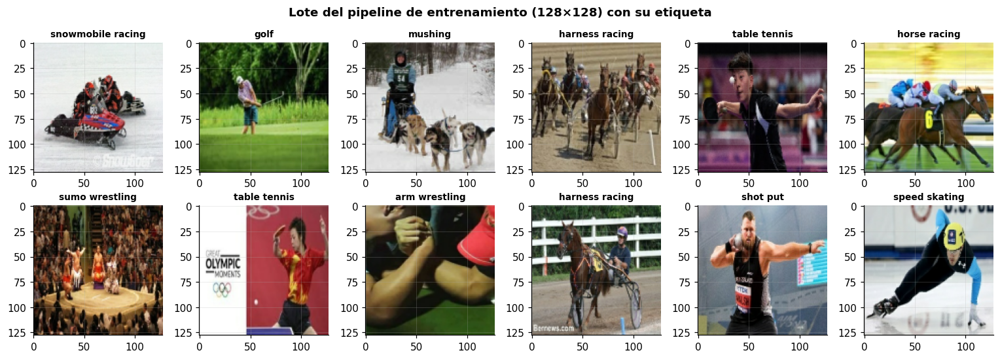

In [ ]:
x, y = next(iter(train_ds))

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x[i].numpy().astype("uint8"))
    ax.set_title(CLASES[int(y[i])], fontsize=9)
    ax.axis("on")
fig.suptitle("Lote del pipeline de entrenamiento (128×128) con su etiqueta", fontweight="bold")
plt.tight_layout()
plt.show()

Como se observa las 12 imágenes del lote coinciden con su etiqueta, por lo que el barajado y la agrupación en lotes mantienen correctamente el emparejamiento imagen-etiqueta. El lote contiene deportes variados, lo que confirma el barajado. Se aprecia también una imagen en escala de grises (wheelchair racing) convertida correctamente a 3 canales.

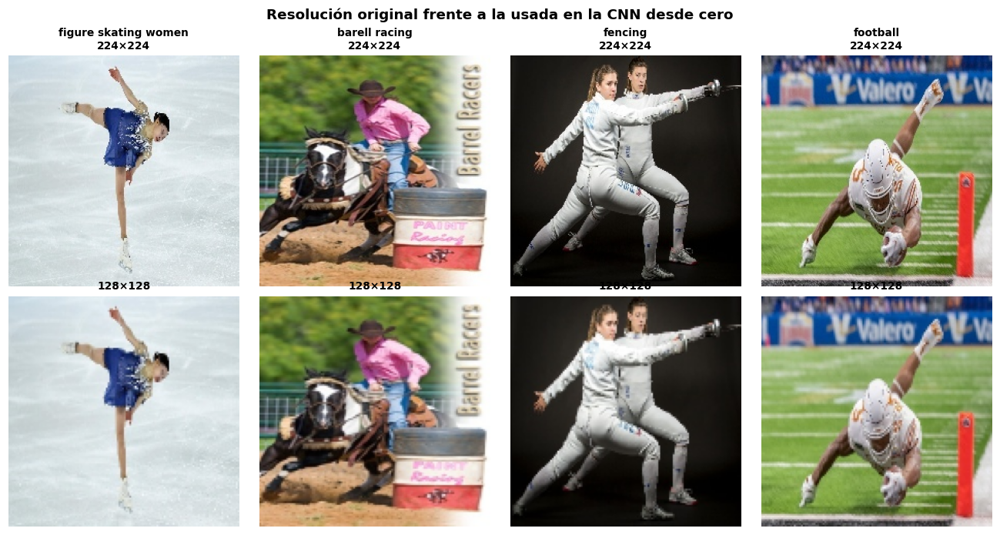

In [ ]:
ejemplos = df[df["split"] == "train"].sample(4, random_state=SEED)

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for j, (_, fila) in enumerate(ejemplos.iterrows()):
    img = Image.open(fila["ruta"]).convert("RGB")
    axes[0, j].imshow(img)
    axes[0, j].set_title(f"{fila['clase']}\n224×224", fontsize=9)
    axes[1, j].imshow(img.resize((IMG_SIZE_SCRATCH, IMG_SIZE_SCRATCH), Image.BOX))
    axes[1, j].set_title(f"{IMG_SIZE_SCRATCH}×{IMG_SIZE_SCRATCH}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Resolución original frente a la usada en la CNN desde cero", fontweight="bold")
plt.tight_layout()
plt.show()

Al reducir las imágenes de 224×224 a 128×128 se pierden detalles finos (la pelota, los números de las camisetas), pero el deporte sigue siendo reconocible a simple vista, ya que se conserva el contexto de la escena: el terreno, el equipamiento y la postura de los deportistas. Esto nos permite trabajar a 128×128 en la CNN desde cero y reducir el coste de cómputo sin perder la información esencial. No obstante, que una persona reconozca la imagen no garantiza que la red lo haga igual de bien, por lo que el efecto de la resolución podrá comprobarse experimentalmente.

## 2.4 Data augmentation

Se aplicará data augmentation para reducir el sobreajuste: en cada época, cada imagen de entrenamiento pasa por una transformación aleatoria distinta (volteo horizontal, rotación, zoom, traslación y contraste) antes de entrar en la red. No se crean imágenes nuevas ni aumenta el tamaño del dataset: en cada época la red sigue viendo 13.492 imágenes, pero con una variación diferente cada vez, de modo que nunca ve exactamente la misma imagen dos veces.

In [ ]:
def crear_augmentation(rotacion=0.04, zoom=0.15, traslacion=0.10, contraste=0.2,
                       nombre="data_augmentation"):
    '''Bloque de data augmentation. Solo actúa en entrenamiento (training=True).'''
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(rotacion, fill_mode="reflect", seed=SEED),
        layers.RandomZoom(zoom, fill_mode="reflect", seed=SEED),
        layers.RandomTranslation(traslacion, traslacion, fill_mode="reflect", seed=SEED),
        layers.RandomContrast(contraste, seed=SEED),
    ], name=nombre)

data_augmentation = crear_augmentation()

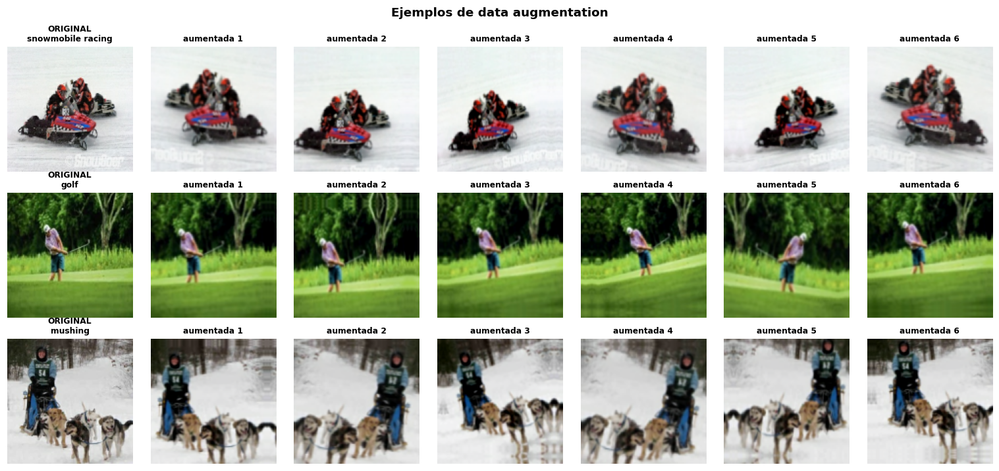

In [ ]:
n_imgs, n_aug = 3, 6
fig, axes = plt.subplots(n_imgs, n_aug + 1, figsize=(14, 2.2 * n_imgs))

for i in range(n_imgs):
    original = x[i:i + 1]
    axes[i, 0].imshow(original[0].numpy().astype("uint8"))
    axes[i, 0].set_title(f"ORIGINAL\n{CLASES[int(y[i])]}", fontsize=8)
    for j in range(1, n_aug + 1):
        aumentada = data_augmentation(original, training=True)
        axes[i, j].imshow(np.clip(aumentada[0].numpy(), 0, 255).astype("uint8"))
        axes[i, j].set_title(f"aumentada {j}", fontsize=8)

for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Ejemplos de data augmentation", fontweight="bold")
plt.tight_layout()
plt.show()

## 2.5 Resumen del preprocesamiento

| Aspecto | Decisión |
|---|---|
| Carga | `image_dataset_from_directory`, etiquetas enteras (0-99), orden de clases fijo |
| Resolución | 128×128 (CNN desde cero) y 224×224 (redes preentrenadas) |
| Normalización | Dentro del modelo: `Rescaling(1/255)` o `preprocess_input` de cada red |
| Rendimiento | Caché en RAM como `uint8`, barajado por época, lotes de 64 y *prefetch* |
| Validación | Split *valid* oficial (500 imágenes); se vigilará sobre todo la *loss* de validación |
| *Data augmentation* | Volteo horizontal, rotación, zoom, traslación y contraste, como capas del modelo; su efecto se evaluará experimentalmente |

# 3. Estrategia 1: CNN desde cero

## 3.1 Modelo base

In [ ]:
modelo_base = keras.Sequential([
    keras.Input(shape=(IMG_SIZE_SCRATCH, IMG_SIZE_SCRATCH, 3)),
    layers.Rescaling(1./255),

    # Bloque 1
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    # Bloque 2
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    # Bloque 3
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    # Bloque 4
    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    # Clasificador
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(N_CLASES, activation="softmax"),
], name="modelo_base")

modelo_base.summary()

Model: "modelo_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,608,676 (17.58 MB)

 Trainable params: 4,608,676 (17.58 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [ ]:
EPOCHS_BASE = 30

t0 = time.time()
historial_base = modelo_base.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_BASE,
    shuffle=False,
    verbose=2,
)
print(f"\nTiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

with open(RESULTS_DIR / "historial_modelo_base.json", "w") as f:
    json.dump({k: [float(v) for v in vs] for k, vs in historial_base.history.items()}, f, indent=2)
modelo_base.save(str(RESULTS_DIR / "modelo_base.keras"))
print("Historial y modelo guardados en", RESULTS_DIR)

Epoch 1/30
211/211 - 48s - 226ms/step - accuracy: 0.0666 - loss: 4.1671 - val_accuracy: 0.1320 - val_loss: 3.5760
Epoch 2/30
211/211 - 9s - 42ms/step - accuracy: 0.2182 - loss: 3.1828 - val_accuracy: 0.2980 - val_loss: 2.7948
Epoch 3/30
211/211 - 9s - 42ms/step - accuracy: 0.3516 - loss: 2.5389 - val_accuracy: 0.3380 - val_loss: 2.5936
Epoch 4/30
211/211 - 10s - 49ms/step - accuracy: 0.4775 - loss: 2.0034 - val_accuracy: 0.4080 - val_loss: 2.2536
Epoch 5/30
211/211 - 9s - 42ms/step - accuracy: 0.5843 - loss: 1.5467 - val_accuracy: 0.4440 - val_loss: 2.2694
Epoch 6/30
211/211 - 9s - 42ms/step - accuracy: 0.7003 - loss: 1.0795 - val_accuracy: 0.4680 - val_loss: 2.3940
Epoch 7/30
211/211 - 9s - 41ms/step - accuracy: 0.8050 - loss: 0.6701 - val_accuracy: 0.4720 - val_loss: 2.7741
Epoch 8/30
211/211 - 9s - 43ms/step - accuracy: 0.8879 - loss: 0.3753 - val_accuracy: 0.4280 - val_loss: 3.1460
Epoch 9/30
211/211 - 9s - 43ms/step - accuracy: 0.9253 - loss: 0.2442 - val_accuracy: 0.4880 - val_lo

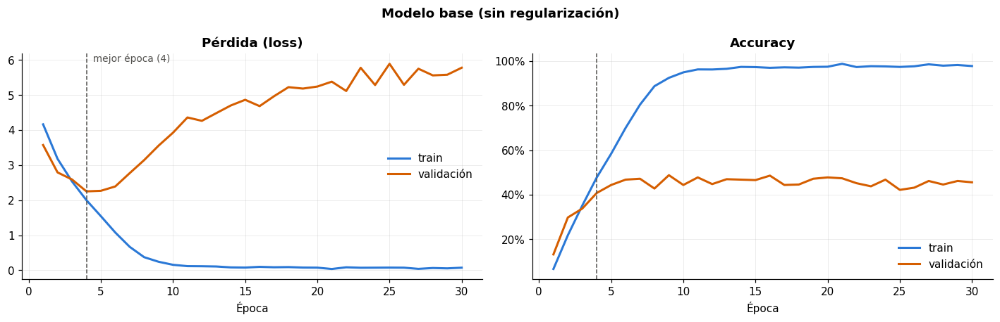

Mejor época (mínima val_loss): 4 -> val_loss = 2.254, val_accuracy = 40.8%
Máxima val_accuracy alcanzada: 48.8%
Última época: train accuracy = 97.8% | val accuracy = 45.6% | diferencia = 52.2 puntos


In [ ]:
from matplotlib.ticker import PercentFormatter

COLOR_TRAIN = "#2a78d6"
COLOR_VAL = "#d55e00"

def resumen_historial(h):
    '''Métricas clave de un entrenamiento a partir de su historial.'''
    h = h.history if hasattr(h, "history") else h
    mejor = int(np.argmin(h["val_loss"]))
    return {
        "mejor_epoca": mejor + 1,
        "val_loss_min": h["val_loss"][mejor],
        "val_acc_en_mejor": h["val_accuracy"][mejor],
        "val_acc_max": max(h["val_accuracy"]),
        "train_acc_final": h["accuracy"][-1],
        "val_acc_final": h["val_accuracy"][-1],
    }

def graficar_historial(h, titulo):
    '''Curvas de loss y accuracy (train y validación) con la mejor época marcada.'''
    h = h.history if hasattr(h, "history") else h
    r = resumen_historial(h)
    epocas = np.arange(1, len(h["loss"]) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, clave, nombre in [(ax1, "loss", "Pérdida (loss)"), (ax2, "accuracy", "Accuracy")]:
        ax.plot(epocas, h[clave], color=COLOR_TRAIN, lw=2, label="train")
        ax.plot(epocas, h["val_" + clave], color=COLOR_VAL, lw=2, label="validación")
        ax.axvline(r["mejor_epoca"], color=COLOR_TEXTO, ls="--", lw=1)
        ax.set_title(nombre)
        ax.set_xlabel("Época")
        ax.legend(frameon=False)
    ax1.text(r["mejor_epoca"], ax1.get_ylim()[1], f"  mejor época ({r['mejor_epoca']})",
             color=COLOR_TEXTO, fontsize=9, va="top")
    ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    plt.show()

    print(f"Mejor época (mínima val_loss): {r['mejor_epoca']} -> val_loss = {r['val_loss_min']:.3f}, "
          f"val_accuracy = {r['val_acc_en_mejor']:.1%}")
    print(f"Máxima val_accuracy alcanzada: {r['val_acc_max']:.1%}")
    print(f"Última época: train accuracy = {r['train_acc_final']:.1%} | "
          f"val accuracy = {r['val_acc_final']:.1%} | "
          f"diferencia = {100 * (r['train_acc_final'] - r['val_acc_final']):.1f} puntos")

graficar_historial(historial_base, "Modelo base (sin regularización)")

**Análisis del modelo base**

Como se puede observar, el modelo sí logra aprender patrones de las imágenes. En la época 4 obtiene su mejor resultado en validación, con un 40,8 % de accuracy y una val_loss de 2,254 (la más baja de todo el entrenamiento), y en la época 9 alcanza su máximo de accuracy en validación con un 48,8 %. Esto es mucho mejor que el 1 % que obtendría un clasificador aleatorio. Además, la pérdida de la primera época (4,17) es cercana a 4,6, que es lo que se espera cuando el modelo todavía reparte las probabilidades al azar entre las 100 clases (ln 100 ≈ 4,6). A partir de la época 5 el modelo empieza a sobreajustarse. La accuracy de entrenamiento sigue subiendo hasta llegar al 98,6 %, pero la de validación se queda estancada entre el 45 % y el 49 % y termina en 45,6 %, por lo que al final hay una diferencia de 52,2 puntos entre las dos. Esto significa que el modelo se está aprendiendo de memoria las imágenes de entrenamiento en lugar de aprender a reconocer los deportes. También se observa que la val_loss sube de 2,25 a 5,78 aunque la accuracy de validación casi no cambia. Esto pasa porque el modelo se vuelve demasiado seguro de sus predicciones, incluso cuando se equivoca, y la pérdida castiga mucho los errores cometidos con mucha seguridad. Por esta razón la val_loss es mejor indicador del sobreajuste que la accuracy, y será la que se use para elegir la mejor época.

Las causas más probables del sobreajuste son tres: el modelo tiene demasiados parámetros para las imágenes disponibles (4,6 millones, el 91 % en la capa Dense que va después del Flatten, para unas 135 imágenes por clase); no se usa data augmentation, por lo que el modelo ve siempre las mismas imágenes; y no se aplica ninguna técnica de regularización. Por eso en los siguientes experimentos se usará early stopping sobre la val_loss y se irán añadiendo técnicas de regularización una por una para medir el efecto de cada una.


## 3.4 Metodología de experimentación

Para que la comparación entre experimentos sea justa, todos se entrenan en las mismas condiciones y cada experimento cambia una sola cosa respecto al anterior. Para ello se definen tres funciones:

- `crear_cnn(...)`: construye la CNN con interruptores para activar cada técnica (data augmentation, dropout, global average pooling, batch normalization). Sin opciones, reproduce exactamente el modelo base.
- `entrenar_experimento(...)`: compila con Adam (lr = 0,001), entrena con ***early stopping*** sobre el `val_loss` (paciencia de 10 épocas, recuperando los pesos de la mejor época), guarda el historial y el modelo, y dibuja las curvas.
- `tabla_resultados()`: tabla comparativa de todos los experimentos, con las métricas en la mejor época.

In [ ]:
def crear_cnn(nombre, augmentation=False, dropout=0.0, gap=False, batchnorm=False,
              filtros=(32, 64, 128, 256)):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    capas = [keras.Input(shape=(IMG_SIZE_SCRATCH, IMG_SIZE_SCRATCH, 3))]
    if augmentation:
        capas.append(crear_augmentation())
    capas.append(layers.Rescaling(1./255))

    for f in filtros:
        capas.append(layers.Conv2D(f, 3, padding="same"))
        if batchnorm:
            capas.append(layers.BatchNormalization())
        capas.append(layers.Activation("relu"))
        capas.append(layers.MaxPooling2D())

    capas.append(layers.GlobalAveragePooling2D() if gap else layers.Flatten())
    if dropout:
        capas.append(layers.Dropout(dropout))
    capas.append(layers.Dense(256, activation="relu"))
    if dropout:
        capas.append(layers.Dropout(dropout))
    capas.append(layers.Dense(N_CLASES, activation="softmax"))
    return keras.Sequential(capas, name=nombre)


print("Parámetros de crear_cnn() sin opciones:", f"{crear_cnn('prueba').count_params():,}")

Parámetros de crear_cnn() sin opciones: 4,608,676


In [ ]:
RESULTADOS = {}   # una fila por experimento: {nombre: {métricas}}

def registrar(nombre, modelo, h, minutos):
    r = resumen_historial(h)
    train_acc_mejor = h["accuracy"][r["mejor_epoca"] - 1]
    RESULTADOS[nombre] = {
        "parámetros": modelo.count_params(),
        "épocas": len(h["loss"]),
        "minutos": round(minutos, 1),
        "mejor época": r["mejor_epoca"],
        "val_loss mín": round(r["val_loss_min"], 3),
        "val_acc": r["val_acc_en_mejor"],
        "train_acc": train_acc_mejor,
        "brecha": train_acc_mejor - r["val_acc_en_mejor"],
    }

def tabla_resultados():
    t = pd.DataFrame(RESULTADOS).T
    t[["épocas", "mejor época"]] = t[["épocas", "mejor época"]].astype(int)
    for col in ["val_acc", "train_acc", "brecha"]:
        t[col] = t[col].map(lambda v: f"{100 * v:.1f} %")
    t["parámetros"] = t["parámetros"].map(lambda v: f"{int(v):,}")
    display(t)

def entrenar_experimento(modelo, nombre, epochs=80, lr=1e-3, paciencia=10):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=paciencia, restore_best_weights=True)

    t0 = time.time()
    historial = modelo.fit(train_ds, validation_data=val_ds, epochs=epochs,
                           callbacks=[early_stopping], shuffle=False, verbose=2)
    minutos = (time.time() - t0) / 60

    h = {k: [float(v) for v in vs] for k, vs in historial.history.items()}
    with open(RESULTS_DIR / f"historial_{nombre}.json", "w") as f:
        json.dump(h, f, indent=2)
    modelo.save(str(RESULTS_DIR / f"{nombre}.keras"))

    registrar(nombre, modelo, h, minutos)
    print(f"\nEntrenamiento: {len(h['loss'])} épocas en {minutos:.1f} min")
    graficar_historial(h, nombre)
    return h

registrar("modelo_base", modelo_base, historial_base.history, 3.7)
tabla_resultados()

,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %


In [ ]:
keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

## 3.5 Experimento 1: *data augmentation*

Epoch 1/80
211/211 - 17s - 80ms/step - accuracy: 0.0479 - loss: 4.3032 - val_accuracy: 0.1060 - val_loss: 3.8073
Epoch 2/80
211/211 - 15s - 70ms/step - accuracy: 0.1562 - loss: 3.4972 - val_accuracy: 0.2440 - val_loss: 3.0784
Epoch 3/80
211/211 - 9s - 41ms/step - accuracy: 0.2697 - loss: 2.9108 - val_accuracy: 0.2900 - val_loss: 2.8129
Epoch 4/80
211/211 - 9s - 42ms/step - accuracy: 0.3392 - loss: 2.5468 - val_accuracy: 0.3960 - val_loss: 2.3335
Epoch 5/80
211/211 - 11s - 52ms/step - accuracy: 0.4048 - loss: 2.2819 - val_accuracy: 0.4300 - val_loss: 2.1538
Epoch 6/80
211/211 - 18s - 87ms/step - accuracy: 0.4481 - loss: 2.0926 - val_accuracy: 0.5000 - val_loss: 1.9259
Epoch 7/80
211/211 - 10s - 48ms/step - accuracy: 0.4931 - loss: 1.8854 - val_accuracy: 0.4820 - val_loss: 1.9645
Epoch 8/80
211/211 - 9s - 42ms/step - accuracy: 0.5325 - loss: 1.7438 - val_accuracy: 0.5300 - val_loss: 1.8085
Epoch 9/80
211/211 - 10s - 46ms/step - accuracy: 0.5511 - loss: 1.6389 - val_accuracy: 0.5560 - val

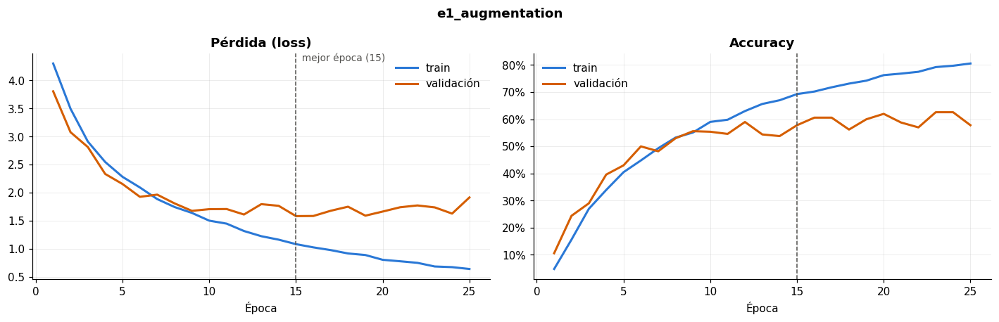

Mejor época (mínima val_loss): 15 -> val_loss = 1.582, val_accuracy = 57.8%
Máxima val_accuracy alcanzada: 62.6%
Última época: train accuracy = 80.6% | val accuracy = 57.8% | diferencia = 22.8 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %


In [ ]:
modelo_e1 = crear_cnn("e1_augmentation", augmentation=True)
h_e1 = entrenar_experimento(modelo_e1, "e1_augmentation")
tabla_resultados()

**Resultados del experimento 1:**

Como se puede observar, el data augmentation mejora bastante el modelo. La accuracy de validación en la mejor época pasa de 40.8 % a 57,8 % (17 puntos más) y la val_loss mínima baja de 2,254 a 1,582.

**Decisión:** se mantiene el data augmentation en los siguientes experimentos y se añade dropout para atacar el sobreajuste que queda.

## 3.6 Experimento 2: data augmentation + dropout

Epoch 1/80
211/211 - 12s - 57ms/step - accuracy: 0.0264 - loss: 4.4445 - val_accuracy: 0.0480 - val_loss: 4.0500
Epoch 2/80
211/211 - 9s - 43ms/step - accuracy: 0.0798 - loss: 3.9438 - val_accuracy: 0.1460 - val_loss: 3.5207
Epoch 3/80
211/211 - 9s - 43ms/step - accuracy: 0.1302 - loss: 3.6426 - val_accuracy: 0.2020 - val_loss: 3.2469
Epoch 4/80
211/211 - 9s - 43ms/step - accuracy: 0.1703 - loss: 3.4011 - val_accuracy: 0.2740 - val_loss: 2.9927
Epoch 5/80
211/211 - 9s - 41ms/step - accuracy: 0.2058 - loss: 3.2087 - val_accuracy: 0.3260 - val_loss: 2.7534
Epoch 6/80
211/211 - 9s - 43ms/step - accuracy: 0.2364 - loss: 3.0397 - val_accuracy: 0.3560 - val_loss: 2.5891
Epoch 7/80
211/211 - 9s - 43ms/step - accuracy: 0.2642 - loss: 2.8987 - val_accuracy: 0.3680 - val_loss: 2.5171
Epoch 8/80
211/211 - 9s - 41ms/step - accuracy: 0.2862 - loss: 2.7861 - val_accuracy: 0.4100 - val_loss: 2.3287
Epoch 9/80
211/211 - 9s - 43ms/step - accuracy: 0.3020 - loss: 2.6864 - val_accuracy: 0.4220 - val_loss

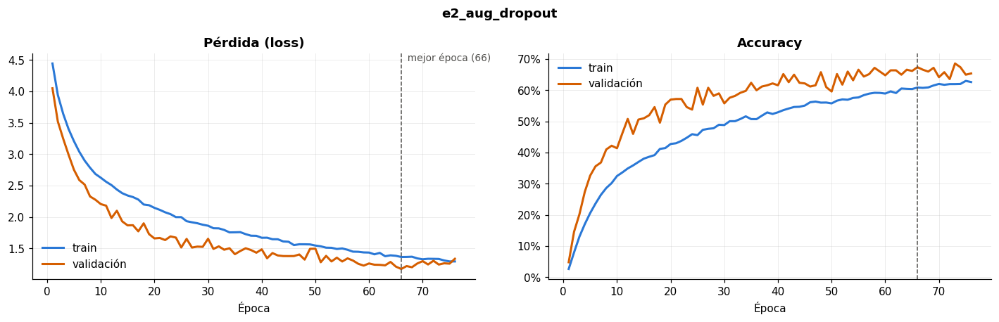

Mejor época (mínima val_loss): 66 -> val_loss = 1.174, val_accuracy = 67.4%
Máxima val_accuracy alcanzada: 68.6%
Última época: train accuracy = 62.6% | val accuracy = 65.4% | diferencia = -2.8 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %


In [ ]:
modelo_e2 = crear_cnn("e2_aug_dropout", augmentation=True, dropout=0.5)
h_e2 = entrenar_experimento(modelo_e2, "e2_aug_dropout")
tabla_resultados()

**Resultados del experimento 2:**

Con el dropout la accuracy de validación sube de 57,8 % a 67,4 % y la val_loss mínima baja de 1,582 a 1,174. Hay que tener en cuenta que, con solo 500 imágenes de validación, una diferencia de casi 10 puntos es más del doble del margen de error, lo que indica que el modelo sí generaliza mejor. El sobreajuste desaparece y la accuracy de validación queda incluso por encima de la de entrenamiento. Esto pasa porque en entrenamiento el modelo trabaja con las imágenes transformadas y con la mitad de las neuronas apagadas, mientras que en validación usa las imágenes originales y todas las neuronas.

Se decide entonces mantener el data augmentation y el dropout. El siguiente paso es simplificar el clasificador, que sigue concentrando casi toda la memoria del modelo, y después buscar formas de que aprenda más rápido.

## 3.7 Experimento 3: GlobalAveragePooling en lugar de Flatten

Epoch 1/80
211/211 - 11s - 54ms/step - accuracy: 0.0175 - loss: 4.5406 - val_accuracy: 0.0180 - val_loss: 4.4461
Epoch 2/80
211/211 - 8s - 40ms/step - accuracy: 0.0314 - loss: 4.3550 - val_accuracy: 0.0520 - val_loss: 4.2060
Epoch 3/80
211/211 - 8s - 38ms/step - accuracy: 0.0467 - loss: 4.1901 - val_accuracy: 0.0680 - val_loss: 3.9593
Epoch 4/80
211/211 - 8s - 40ms/step - accuracy: 0.0712 - loss: 3.9577 - val_accuracy: 0.1000 - val_loss: 3.6835
Epoch 5/80
211/211 - 10s - 48ms/step - accuracy: 0.0969 - loss: 3.7637 - val_accuracy: 0.1480 - val_loss: 3.4675
Epoch 6/80
211/211 - 8s - 38ms/step - accuracy: 0.1218 - loss: 3.6179 - val_accuracy: 0.1740 - val_loss: 3.3578
Epoch 7/80
211/211 - 9s - 40ms/step - accuracy: 0.1396 - loss: 3.4871 - val_accuracy: 0.2220 - val_loss: 3.1879
Epoch 8/80
211/211 - 8s - 39ms/step - accuracy: 0.1585 - loss: 3.3708 - val_accuracy: 0.2120 - val_loss: 3.1136
Epoch 9/80
211/211 - 8s - 39ms/step - accuracy: 0.1737 - loss: 3.2769 - val_accuracy: 0.2540 - val_los

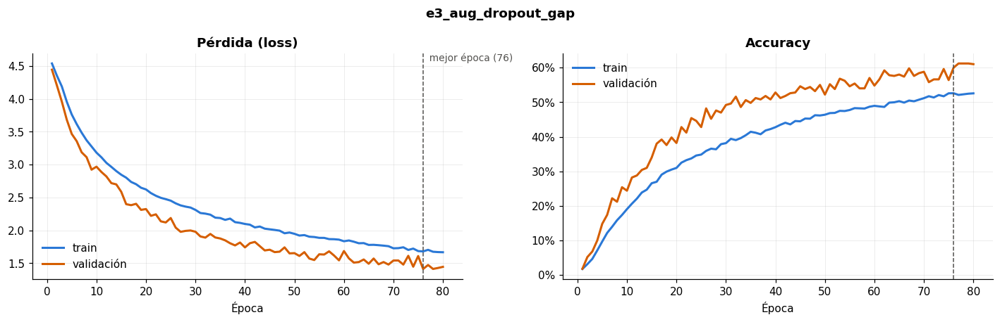

Mejor época (mínima val_loss): 76 -> val_loss = 1.412, val_accuracy = 60.0%
Máxima val_accuracy alcanzada: 61.2%
Última época: train accuracy = 52.6% | val accuracy = 61.0% | diferencia = -8.4 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %
e3_aug_dropout_gap,"479,908",80,11.4,76,1.412,60.0 %,52.6 %,-7.4 %


In [ ]:
modelo_e3 = crear_cnn("e3_aug_dropout_gap", augmentation=True, dropout=0.5, gap=True)
h_e3 = entrenar_experimento(modelo_e3, "e3_aug_dropout_gap")
tabla_resultados()

**Resultados del experimento 3:**


El resultado empeora: la accuracy de validación baja de 67,4 % a 60,0 % (7,4 % menos). Esta diferencia supera el margen de error de la validación (unos ±4 puntos), por lo que sí se puede afirmar que este modelo rinde peor. Hay que tener en cuenta que el entrenamiento llegó al límite de 80 épocas sin que el early stopping lo detuviera: la mejor época fue la 76 y las curvas todavía estaban bajando. Es decir, el modelo no terminó de aprender por lo que su resultado está subestimado.

Se mantiene el GlobalAveragePooling porque reduce el modelo un 90 % y el problema actual es que aprende despacio, no que sobreajuste.

En el siguiente experimento se añade Batch Normalization para que el modelo aprenda más rápido. Además, se aumenta el máximo de épocas a 120 para que el entrenamiento no se corte antes de tiempo.

## 3.8 Experimento 4: + Batch Normalization

Epoch 1/120
211/211 - 25s - 120ms/step - accuracy: 0.0344 - loss: 4.4475 - val_accuracy: 0.0240 - val_loss: 4.4652
Epoch 2/120
211/211 - 19s - 90ms/step - accuracy: 0.0731 - loss: 3.9848 - val_accuracy: 0.0580 - val_loss: 3.9694
Epoch 3/120
211/211 - 19s - 90ms/step - accuracy: 0.1056 - loss: 3.7352 - val_accuracy: 0.1160 - val_loss: 3.5138
Epoch 4/120
211/211 - 19s - 89ms/step - accuracy: 0.1287 - loss: 3.5582 - val_accuracy: 0.1400 - val_loss: 3.4765
Epoch 5/120
211/211 - 19s - 90ms/step - accuracy: 0.1495 - loss: 3.4420 - val_accuracy: 0.1540 - val_loss: 3.3625
Epoch 6/120
211/211 - 19s - 89ms/step - accuracy: 0.1737 - loss: 3.3166 - val_accuracy: 0.0520 - val_loss: 6.6943
Epoch 7/120
211/211 - 19s - 89ms/step - accuracy: 0.1854 - loss: 3.2048 - val_accuracy: 0.1220 - val_loss: 3.4762
Epoch 8/120
211/211 - 19s - 90ms/step - accuracy: 0.2027 - loss: 3.1207 - val_accuracy: 0.1440 - val_loss: 3.4290
Epoch 9/120
211/211 - 19s - 89ms/step - accuracy: 0.2125 - loss: 3.0794 - val_accuracy:

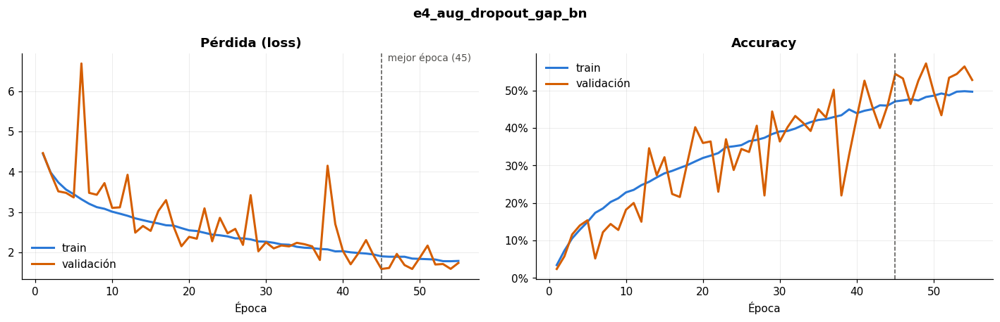

Mejor época (mínima val_loss): 45 -> val_loss = 1.583, val_accuracy = 54.4%
Máxima val_accuracy alcanzada: 57.2%
Última época: train accuracy = 49.7% | val accuracy = 52.8% | diferencia = -3.1 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %
e3_aug_dropout_gap,"479,908",80,11.4,76,1.412,60.0 %,52.6 %,-7.4 %
e4_aug_dropout_gap_bn,"481,828",55,17.6,45,1.583,54.4 %,47.1 %,-7.3 %


In [ ]:
modelo_e4 = crear_cnn("e4_aug_dropout_gap_bn", augmentation=True, dropout=0.5, gap=True, batchnorm=True)
h_e4 = entrenar_experimento(modelo_e4, "e4_aug_dropout_gap_bn", epochs=120)
tabla_resultados()

**Resultados del experimento 4:**

La Batch Normalization empeora claramente el modelo: la accuracy de validación baja de 60 % a 54,4 % y la val_loss mínima sube de 1,41 a 1,58, por lo que se rechaza la hipótesis. La curva de validación es muy inestable, con saltos bruscos, mientras que la de entrenamiento es suave. Esto se explica porque la Batch Normalization funciona de forma distinta en entrenamiento, donde usa las estadísticas de cada lote, y en evaluación, donde usa un promedio acumulado.

Se descarta la Batch Normalization y se vuelve a la configuración del experimento 3. Como el problema ahora es que el modelo está demasiado frenado, el siguiente paso es reducir el dropout.

## 3.9 Experimento 5: reducción del dropout

Epoch 1/120
211/211 - 11s - 52ms/step - accuracy: 0.0188 - loss: 4.5099 - val_accuracy: 0.0280 - val_loss: 4.3574
Epoch 2/120
211/211 - 8s - 39ms/step - accuracy: 0.0417 - loss: 4.2631 - val_accuracy: 0.0620 - val_loss: 4.1290
Epoch 3/120
211/211 - 9s - 41ms/step - accuracy: 0.0664 - loss: 4.0297 - val_accuracy: 0.0780 - val_loss: 3.8337
Epoch 4/120
211/211 - 8s - 39ms/step - accuracy: 0.1085 - loss: 3.7365 - val_accuracy: 0.1780 - val_loss: 3.4203
Epoch 5/120
211/211 - 9s - 42ms/step - accuracy: 0.1571 - loss: 3.4380 - val_accuracy: 0.2360 - val_loss: 3.0991
Epoch 6/120
211/211 - 9s - 41ms/step - accuracy: 0.1907 - loss: 3.2311 - val_accuracy: 0.2600 - val_loss: 2.8985
Epoch 7/120
211/211 - 9s - 41ms/step - accuracy: 0.2280 - loss: 3.0647 - val_accuracy: 0.2940 - val_loss: 2.7595
Epoch 8/120
211/211 - 9s - 42ms/step - accuracy: 0.2501 - loss: 2.9386 - val_accuracy: 0.3200 - val_loss: 2.6343
Epoch 9/120
211/211 - 10s - 46ms/step - accuracy: 0.2775 - loss: 2.8126 - val_accuracy: 0.3520 

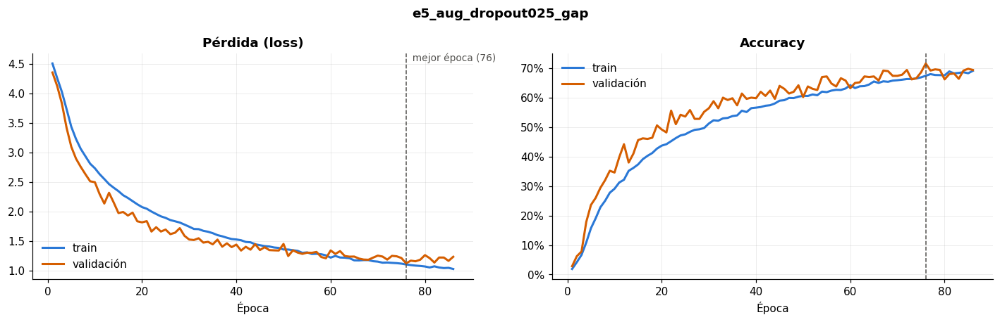

Mejor época (mínima val_loss): 76 -> val_loss = 1.127, val_accuracy = 71.6%
Máxima val_accuracy alcanzada: 71.6%
Última época: train accuracy = 69.1% | val accuracy = 69.4% | diferencia = -0.3 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %
e3_aug_dropout_gap,"479,908",80,11.4,76,1.412,60.0 %,52.6 %,-7.4 %
e4_aug_dropout_gap_bn,"481,828",55,17.6,45,1.583,54.4 %,47.1 %,-7.3 %
e5_aug_dropout025_gap,"479,908",86,12.8,76,1.127,71.6 %,67.4 %,-4.2 %


In [ ]:
modelo_e5 = crear_cnn("e5_aug_dropout025_gap", augmentation=True, dropout=0.25, gap=True)
h_e5 = entrenar_experimento(modelo_e5, "e5_aug_dropout025_gap", epochs=120)
tabla_resultados()

**Resultados del experimento 5:**

Al reducir el dropout de 0,5 a 0,25 se obtiene el mejor modelo hasta ahora: la accuracy de validación a 71.6 % y la val_loss mínima baja a 1,13, la más baja de todos los experimentos, incluso por debajo del experimento 2, que tenía 10 veces más parámetros. Como se esperaba, el modelo aprende más rápido y el entrenamiento se detiene solo en la época 86 sin llegar al límite.

Se seguirá trabajando con esta configuración (data augmentation + dropout 0,25 + GlobalAveragePooling) como la mejor. Como el modelo ya está equilibrado, el siguiente paso es darle más capacidad para que pueda aprender patrones más complejos.

## 3.10 Experimento 6: más capacidad (quinto bloque convolucional)

Epoch 1/120
211/211 - 17s - 79ms/step - accuracy: 0.0231 - loss: 4.4743 - val_accuracy: 0.0340 - val_loss: 4.2918
Epoch 2/120
211/211 - 10s - 47ms/step - accuracy: 0.0488 - loss: 4.1724 - val_accuracy: 0.0680 - val_loss: 3.9822
Epoch 3/120
211/211 - 10s - 46ms/step - accuracy: 0.0854 - loss: 3.8279 - val_accuracy: 0.1120 - val_loss: 3.5089
Epoch 4/120
211/211 - 10s - 46ms/step - accuracy: 0.1287 - loss: 3.5370 - val_accuracy: 0.1840 - val_loss: 3.2192
Epoch 5/120
211/211 - 9s - 43ms/step - accuracy: 0.1806 - loss: 3.2904 - val_accuracy: 0.2400 - val_loss: 2.9943
Epoch 6/120
211/211 - 10s - 45ms/step - accuracy: 0.2206 - loss: 3.0620 - val_accuracy: 0.3160 - val_loss: 2.6633
Epoch 7/120
211/211 - 11s - 52ms/step - accuracy: 0.2625 - loss: 2.8498 - val_accuracy: 0.3040 - val_loss: 2.6962
Epoch 8/120
211/211 - 9s - 44ms/step - accuracy: 0.2943 - loss: 2.7157 - val_accuracy: 0.3640 - val_loss: 2.4714
Epoch 9/120
211/211 - 11s - 51ms/step - accuracy: 0.3305 - loss: 2.5492 - val_accuracy: 0.

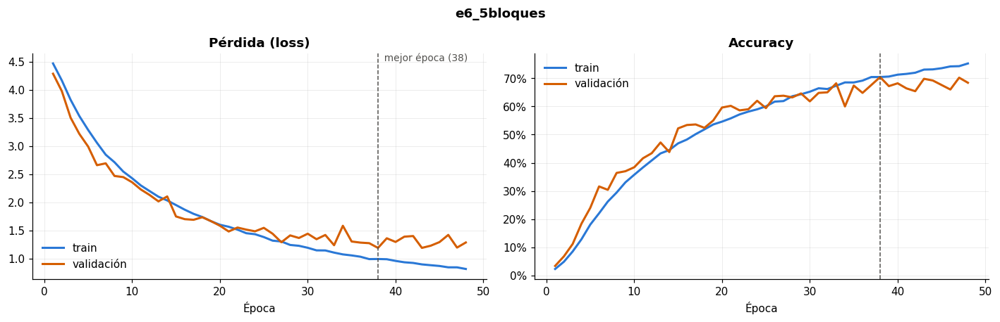

Mejor época (mínima val_loss): 38 -> val_loss = 1.191, val_accuracy = 70.4%
Máxima val_accuracy alcanzada: 70.4%
Última época: train accuracy = 75.2% | val accuracy = 68.4% | diferencia = 6.8 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %
e3_aug_dropout_gap,"479,908",80,11.4,76,1.412,60.0 %,52.6 %,-7.4 %
e4_aug_dropout_gap_bn,"481,828",55,17.6,45,1.583,54.4 %,47.1 %,-7.3 %
e5_aug_dropout025_gap,"479,908",86,12.8,76,1.127,71.6 %,67.4 %,-4.2 %
e6_5bloques,"1,725,604",48,8.0,38,1.191,70.4 %,70.4 %,0.0 %


In [ ]:
modelo_e6 = crear_cnn("e6_5bloques", augmentation=True, dropout=0.25, gap=True,
                      filtros=(32, 64, 128, 256, 512))
h_e6 = entrenar_experimento(modelo_e6, "e6_5bloques", epochs=120)
tabla_resultados()

**Resultados del experimento 6:**

Añadir un quinto bloque no mejora el modelo respecto al experimento 5: la accuracy de validación pasa de 71,6 % a 70,4 % (dentro del margen de error de ±4 puntos) y la val_loss mínima sube de 1,13 a 1,19. Aun así, el modelo converge mucho antes (mejor época 38 frente a 76, y 8,0 min frente a 12,8) y no hay sobreajuste: la brecha entre entrenamiento y validación es de 0,0 puntos. Tiene 1,7 millones de parámetros, casi 3 veces menos que el modelo base.

Decisión: se toma esta arquitectura como la definitiva para la estrategia desde cero, por casi igualar el rendimiento del experimento 5 con una convergencia más rápida. Para el modelo final se entrenará con un learning rate que se reduce automáticamente cuando la val_loss deja de mejorar.

## 3.11 Modelo final de la estrategia desde cero

Epoch 1/150
211/211 - 13s - 62ms/step - accuracy: 0.0167 - loss: 4.5302 - val_accuracy: 0.0260 - val_loss: 4.4656 - learning_rate: 0.0010
Epoch 2/150
211/211 - 10s - 46ms/step - accuracy: 0.0402 - loss: 4.2843 - val_accuracy: 0.0680 - val_loss: 4.0289 - learning_rate: 0.0010
Epoch 3/150
211/211 - 10s - 49ms/step - accuracy: 0.0765 - loss: 3.9538 - val_accuracy: 0.1000 - val_loss: 3.7127 - learning_rate: 0.0010
Epoch 4/150
211/211 - 21s - 98ms/step - accuracy: 0.1146 - loss: 3.6490 - val_accuracy: 0.1760 - val_loss: 3.2825 - learning_rate: 0.0010
Epoch 5/150
211/211 - 9s - 45ms/step - accuracy: 0.1692 - loss: 3.3384 - val_accuracy: 0.1980 - val_loss: 3.0327 - learning_rate: 0.0010
Epoch 6/150
211/211 - 10s - 48ms/step - accuracy: 0.2069 - loss: 3.1169 - val_accuracy: 0.2540 - val_loss: 2.8026 - learning_rate: 0.0010
Epoch 7/150
211/211 - 10s - 46ms/step - accuracy: 0.2409 - loss: 2.9461 - val_accuracy: 0.2900 - val_loss: 2.6726 - learning_rate: 0.0010
Epoch 8/150
211/211 - 10s - 45ms/st

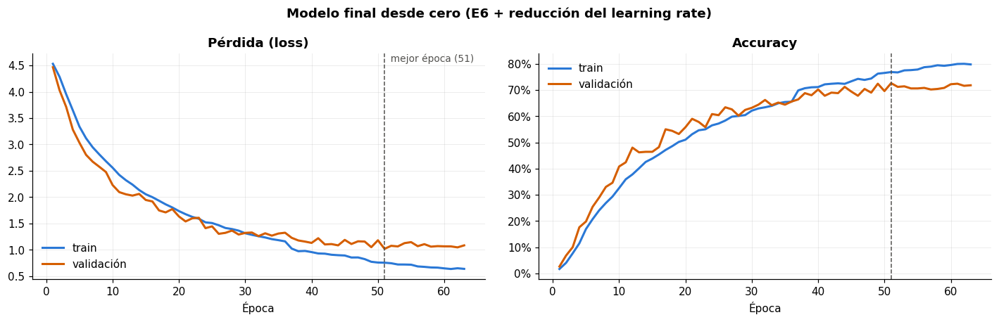

Mejor época (mínima val_loss): 51 -> val_loss = 1.019, val_accuracy = 72.6%
Máxima val_accuracy alcanzada: 72.6%
Última época: train accuracy = 79.8% | val accuracy = 71.8% | diferencia = 8.0 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %
e3_aug_dropout_gap,"479,908",80,11.4,76,1.412,60.0 %,52.6 %,-7.4 %
e4_aug_dropout_gap_bn,"481,828",55,17.6,45,1.583,54.4 %,47.1 %,-7.3 %
e5_aug_dropout025_gap,"479,908",86,12.8,76,1.127,71.6 %,67.4 %,-4.2 %
e6_5bloques,"1,725,604",48,8.0,38,1.191,70.4 %,70.4 %,0.0 %
cnn_final_scratch,"1,725,604",63,10.3,51,1.019,72.6 %,76.9 %,4.3 %


In [ ]:
NOMBRE_FINAL = "cnn_final_scratch"

modelo_final = crear_cnn(NOMBRE_FINAL, augmentation=True, dropout=0.25, gap=True,
                         filtros=(32, 64, 128, 256, 512))
modelo_final.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                     loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4,
                                      min_lr=1e-5, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
]

t0 = time.time()
historial = modelo_final.fit(train_ds, validation_data=val_ds, epochs=150,
                             callbacks=callbacks, shuffle=False, verbose=2)
minutos = (time.time() - t0) / 60

h_final = {k: [float(v) for v in vs] for k, vs in historial.history.items()}
with open(RESULTS_DIR / f"historial_{NOMBRE_FINAL}.json", "w") as f:
    json.dump(h_final, f, indent=2)
modelo_final.save(str(RESULTS_DIR / f"{NOMBRE_FINAL}.keras"))

registrar(NOMBRE_FINAL, modelo_final, h_final, minutos)
print(f"\nEntrenamiento: {len(h_final['loss'])} épocas en {minutos:.1f} min")
graficar_historial(h_final, "Modelo final desde cero (E6 + reducción del learning rate)")
tabla_resultados()

In [ ]:
test_loss, test_acc = modelo_final.evaluate(test_ds, verbose=0)
n_test = int((df["split"] == "test").sum())
margen = 1.96 * np.sqrt(test_acc * (1 - test_acc) / n_test)

print(f"Accuracy en TEST : {test_acc:.1%}   (IC 95 %: {test_acc - margen:.1%} a {test_acc + margen:.1%})")
print(f"Loss en TEST     : {test_loss:.3f}")
print(f"Accuracy en VALIDACIÓN (mejor época): {RESULTADOS[NOMBRE_FINAL]['val_acc']:.1%}")
print(f"Clasificador trivial: {acc_aleatorio:.1%}")

with open(RESULTS_DIR / "test_cnn_scratch.json", "w") as f:
    json.dump({"modelo": NOMBRE_FINAL, "test_acc": float(test_acc), "test_loss": float(test_loss),
               "ic95": float(margen), "val_acc": float(RESULTADOS[NOMBRE_FINAL]["val_acc"]),
               "parametros": int(modelo_final.count_params())}, f, indent=2)

Accuracy en TEST : 74.2%   (IC 95 %: 70.4% a 78.0%)
Loss en TEST     : 0.945
Accuracy en VALIDACIÓN (mejor época): 72.6%
Clasificador trivial: 1.0%


**Resultados del modelo final:**

Con la reducción automática del learning rate, el modelo alcanza un 72,6 % de accuracy en validación y una val_loss de 1,019, ligeramente mejor que el experimento 5 y 6. En las curvas se observa el efecto de la reducción del learning rate a partir de la época 37, justo después de la primera reducción del learning rate (época 36): la pérdida de entrenamiento baja de golpe y la validación también mejora, ya que con pasos más pequeños el modelo encuentra un mejor punto.

Además, en el conjunto de test el modelo obtiene un 74,2 % de accuracy (IC 95 %: 70,4 % a 78,0 %). Esto indica que las decisiones tomadas con el conjunto de validación no hicieron que el modelo se ajustara a esas imágenes en particular, y que el resultado es una estimación fiable de cómo funciona con imágenes nuevas.

El resultado es 74 veces mejor que el de un clasificador trivial (1 %), teniendo en cuenta que hay 100 clases y solo unas 135 imágenes de entrenamiento por clase.

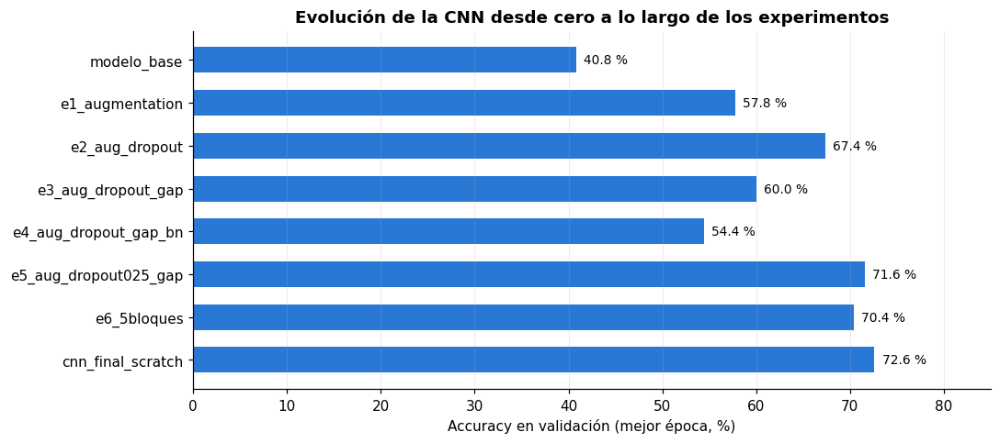

In [ ]:
nombres = list(RESULTADOS.keys())
val_accs = [100 * RESULTADOS[n]["val_acc"] for n in nombres]

fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.barh(nombres, val_accs, color=COLOR, height=0.6)
ax.invert_yaxis()
for barra, v in zip(barras, val_accs):
    ax.text(v + 0.8, barra.get_y() + barra.get_height() / 2, f"{v:.1f} %", va="center", fontsize=9)
ax.set_xlim(0, 85)
ax.set_xlabel("Accuracy en validación (mejor época, %)")
ax.set_title("Evolución de la CNN desde cero a lo largo de los experimentos")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3.12 Conclusiones de la estrategia CNN desde cero

- El modelo base sin regularización memoriza las imágenes de entrenamiento rápidamente: al final llega a un 97,8 % de accuracy en entrenamiento frente a un 45,6 % en validación (52,2 puntos de diferencia). Con solo unas 135 imágenes por clase, controlar el sobreajuste es el principal reto de esta estrategia.
- El data augmentation es la técnica con mayor impacto: la accuracy de validación pasa de 40,8 % a 57,8 % (+17 puntos), ya que el modelo nunca ve exactamente la misma imagen dos veces. El dropout (0,5) añade otros 9,6 puntos (67,4 %) y hace desaparecer el sobreajuste.
- Con dropout 0,5, cambiar el Flatten por GlobalAveragePooling empeora el modelo (60,0 %), porque la regularización total es excesiva y el modelo queda frenado (subajuste). Al reducir el dropout a 0,25 se obtiene el mejor resultado de todos los experimentos (71,6 %) con solo 480.000 parámetros, un 90 % menos que el modelo base. Esto muestra que las técnicas de regularización interactúan entre sí y que hay que buscar el equilibrio entre aprender y no memorizar.
- La Batch Normalization empeoró el modelo (de 60,0 % a 54,4 %) y volvió inestable la validación, por lo que se descartó.
- Añadir un quinto bloque convolucional no mejoró la accuracy de validación (70,4 % frente a 71,6 %, dentro del margen de error), pero el modelo convergió en la mitad de épocas (38 frente a 76), por lo que se eligió como arquitectura final.
- Con la reducción automática del learning rate, el modelo final alcanza un 72,6 % en validación y un **74,2 % en test** (IC 95 %: 70,4 % a 78,0 %), con 1,7 millones de parámetros y 10,3 minutos de entrenamiento: 74 veces mejor que un clasificador trivial.
- **Limitaciones:** las imágenes se redujeron a 128×128 para acelerar los experimentos, y cada experimento se entrenó una sola vez, por lo que parte de las diferencias pueden deberse al azar del entrenamiento; con 500 imágenes de validación, las diferencias menores de unos 4 puntos no son concluyentes.

# 4. Estrategia 2: utilización de una red preentrenada

Las 2 redes preentrenadas a realizar son ResNet50V2 y MobileNetV2 se eligen por contraste. ResNet50V2 representa una red grande, y MobileNetV2 una red unas 10 veces más pequeña. Esto permite comparar no solo la *accuracy*, sino también el coste (parámetros y tiempo de entrenamiento).

| | **ResNet50V2** | **MobileNetV2** |
|---|---|---|
| Parámetros de la base | ≈ 23,6 M | ≈ 2,3 M |
| Salida de la base (entrada 224×224) | 7×7×2048 | 7×7×1280 |
| Normalización de entrada | [−1, 1] | [−1, 1] |
| Perfil | Red profunda y potente, más costosa | Red ligera, pensada para dispositivos con pocos recursos |

In [ ]:
from tensorflow.keras.applications.resnet_v2 import preprocess_input as pp_resnet
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as pp_mobilenet

## 4.1 Transfer Learning
La entrada nativa de ambas redes para las imágenes es de 224×224 píxeles, así que no hace falta redimensionarlas

In [ ]:
train_ds_tl, val_ds_tl, test_ds_tl = crear_datasets(IMG_SIZE_TL)
for nombre, ds in [("train", train_ds_tl), ("valid", val_ds_tl), ("test", test_ds_tl)]:
    print(f"{nombre:<6}: {ds.cardinality().numpy()} paquetes")

x_tl, y_tl = next(iter(train_ds_tl))
print("\nForma del lote:", x_tl.shape, "| tipo:", x_tl.dtype)

Found 13492 files belonging to 100 classes.
Found 500 files belonging to 100 classes.
Found 500 files belonging to 100 classes.
train : 211 paquetes
valid : 8 paquetes
test  : 8 paquetes

Forma del lote: (64, 224, 224, 3) | tipo: <dtype: 'float32'>


Se crea y se entrena en el modelo en las 2 siguiente funciones:
- **crear_modelo_tl(...):** construye entrada → data augmentation → preprocesado → base congelada → GlobalAveragePooling → Dropout → Dense(100). Con el `training=False` se hace que se usen siempre las estadísticas aprendidas en ImageNet.

- **entrenar_experimento_tl(...):** igual que `entrenar_experimento` de la sección 3.4, pero usando los datasets a 224×224 y con el learning rate, las épocas y la paciencia como parámetros.

Cabe aclarar que utilizaremos augmentation tanto en Transfer-Learning como en fine-tuning

In [ ]:
ARQUITECTURAS = {
    "resnet50v2":  (keras.applications.ResNet50V2,  "conv5_block1_preact_bn"),
    "mobilenetv2": (keras.applications.MobileNetV2, "block_13_expand"),
}

PARAMS_ENTRENABLES = {}   # {experimento: nº de parámetros entrenables}

def crear_modelo_tl(nombre, arquitectura, augmentation=True, dropout=0.5):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    constructor, _ = ARQUITECTURAS[arquitectura]
    base = constructor(include_top=False, weights="imagenet",
                       input_shape=(IMG_SIZE_TL, IMG_SIZE_TL, 3), name=arquitectura)
    base.trainable = False

    entrada = keras.Input(shape=(IMG_SIZE_TL, IMG_SIZE_TL, 3))
    x = crear_augmentation()(entrada) if augmentation else entrada
    x = layers.Rescaling(1./127.5, offset=-1, name="preprocesado")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    salida = layers.Dense(N_CLASES, activation="softmax")(x)
    return keras.Model(entrada, salida, name=nombre)

def entrenar_experimento_tl(modelo, nombre, epochs=40, lr=1e-3, paciencia=8):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=paciencia, restore_best_weights=True)

    t0 = time.time()
    historial = modelo.fit(train_ds_tl, validation_data=val_ds_tl, epochs=epochs,
                           callbacks=[early_stopping], shuffle=False, verbose=2)
    minutos = (time.time() - t0) / 60

    h = {k: [float(v) for v in vs] for k, vs in historial.history.items()}
    with open(RESULTS_DIR / f"historial_{nombre}.json", "w") as f:
        json.dump(h, f, indent=2)
    modelo.save(str(RESULTS_DIR / f"{nombre}.keras"))

    registrar(nombre, modelo, h, minutos)
    PARAMS_ENTRENABLES[nombre] = int(sum(np.prod(w.shape) for w in modelo.trainable_weights))
    print(f"\nEntrenamiento: {len(h['loss'])} épocas en {minutos:.1f} min "
          f"({PARAMS_ENTRENABLES[nombre]:,} parámetros entrenables)")
    graficar_historial(h, nombre)
    return h

In [ ]:
for arq in ARQUITECTURAS:
    m = crear_modelo_tl("prueba", arq)
    print(f"{arq:<12} total = {m.count_params():>11,} | base = {m.get_layer(arq).count_params():>11,} | "
          f"entrenables (solo clasificador) = {int(sum(np.prod(w.shape) for w in m.trainable_weights)):>9,}")

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
resnet50v2   total =  23,769,700 | base =  23,564,800 | entrenables (solo clasificador) =   204,900
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
mobilenetv2  total =   2,386,084 | base =   2,257,984 | entrenables (solo clasificador) =   128,100


### 4.1.1 ResNet50V2

Model: "e7_resnet50v2_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesado (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       204,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,769,700 (90.67 MB)

 Trainable params: 204,900 (800.39 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/40
211/211 - 71s - 336ms/step - accuracy: 0.4018 - loss: 2.5153 - val_accuracy: 0.8240 - val_loss: 0.6921
Epoch 2/40
211/211 - 49s - 232ms/step - accuracy: 0.6877 - loss: 1.1333 - val_accuracy: 0.8620 - val_loss: 0.4843
Epoch 3/40
211/211 - 49s - 233ms/step - accuracy: 0.7487 - loss: 0.8840 - val_accuracy: 0.8940 - val_loss: 0.3723
Epoch 4/40
211/211 - 49s - 234ms/step - accuracy: 0.7811 - loss: 0.7648 - val_accuracy: 0.9020 - val_loss: 0.3619
Epoch 5/40
211/211 - 83s - 393ms/step - accuracy: 0.8025 - loss: 0.6762 - val_accuracy: 0.9120 - val_loss: 0.3330
Epoch 6/40
211/211 - 49s - 231ms/step - accuracy: 0.8060 - loss: 0.6504 - val_accuracy: 0.8940 - val_loss: 0.3296
Epoch 7/40
211/211 - 49s - 234ms/step - accuracy: 0.8220 - loss: 0.6047 - val_accuracy: 0.9080 - val_loss: 0.3262
Epoch 8/40
211/211 - 49s - 233ms/step - accuracy: 0.8253 - loss: 0.5747 - val_accuracy: 0.9080 - val_loss: 0.3065
Epoch 9/40
211/211 - 49s - 233ms/step - accuracy: 0.8329 - loss: 0.5487 - val_accuracy: 

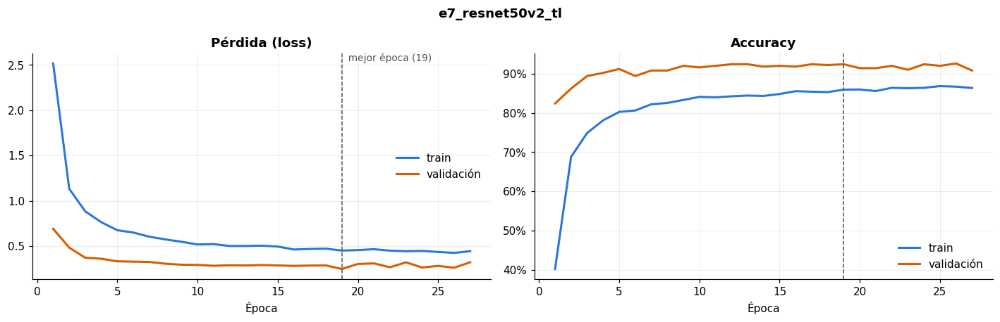

Mejor época (mínima val_loss): 19 -> val_loss = 0.249, val_accuracy = 92.4%
Máxima val_accuracy alcanzada: 92.6%
Última época: train accuracy = 86.3% | val accuracy = 90.8% | diferencia = -4.5 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %
e3_aug_dropout_gap,"479,908",80,11.4,76,1.412,60.0 %,52.6 %,-7.4 %
e4_aug_dropout_gap_bn,"481,828",55,17.6,45,1.583,54.4 %,47.1 %,-7.3 %
e5_aug_dropout025_gap,"479,908",86,12.8,76,1.127,71.6 %,67.4 %,-4.2 %
e6_5bloques,"1,725,604",48,8.0,38,1.191,70.4 %,70.4 %,0.0 %
cnn_final_scratch,"1,725,604",63,10.3,51,1.019,72.6 %,76.9 %,4.3 %
e7_resnet50v2_tl,"23,769,700",27,24.1,19,0.249,92.4 %,85.9 %,-6.5 %


In [ ]:
modelo_e7 = crear_modelo_tl("e7_resnet50v2_tl", "resnet50v2")
modelo_e7.summary()
h_e7 = entrenar_experimento_tl(modelo_e7, "e7_resnet50v2_tl")
tabla_resultados()

**Resultados del experimento 7:**

Podemos ver que al usar ResNet50V2 preentrenada con la base congelada mejora el modelo de forma muy clara: la accuracy de validación sube de 72,6 % (mejor modelo desde cero) a 92,4 % y la val_loss mínima baja de 1,02 a 0,25, una mejora de casi 20  puntos, muy por encima del margen de error de la validación. Las características aprendidas en ImageNet resultan muy útiles para reconocer deportes, y eso con solo 204.900 parámetros entrenables, frente a los 1,7 millones del modelo desde cero. No hay sobreajuste: en la mejor época (19) la accuracy de entrenamiento queda por debajo de la de validación, porque en entrenamiento se aplican data augmentation y dropout. El coste es el tiempo: 24,1 minutos frente a 10,3, ya que la red tiene 23,8 millones de parámetros y cada época es mucho más lenta.


### 4.1.2 MobileNetV2

Model: "e8_mobilenetv2_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesado (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2 (Functional)        │ (None, 7, 7, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       128,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,386,084 (9.10 MB)

 Trainable params: 128,100 (500.39 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/40
211/211 - 36s - 170ms/step - accuracy: 0.3670 - loss: 2.6688 - val_accuracy: 0.7700 - val_loss: 0.9166
Epoch 2/40
211/211 - 25s - 117ms/step - accuracy: 0.6645 - loss: 1.2181 - val_accuracy: 0.8260 - val_loss: 0.5909
Epoch 3/40
211/211 - 24s - 116ms/step - accuracy: 0.7373 - loss: 0.9312 - val_accuracy: 0.8720 - val_loss: 0.4471
Epoch 4/40
211/211 - 25s - 118ms/step - accuracy: 0.7743 - loss: 0.7862 - val_accuracy: 0.8820 - val_loss: 0.3941
Epoch 5/40
211/211 - 25s - 120ms/step - accuracy: 0.7956 - loss: 0.7147 - val_accuracy: 0.8900 - val_loss: 0.3825
Epoch 6/40
211/211 - 25s - 117ms/step - accuracy: 0.8044 - loss: 0.6713 - val_accuracy: 0.8860 - val_loss: 0.3437
Epoch 7/40
211/211 - 25s - 119ms/step - accuracy: 0.8149 - loss: 0.6221 - val_accuracy: 0.8900 - val_loss: 0.3374
Epoch 8/40
211/211 - 25s - 119ms/step - accuracy: 0.8192 - loss: 0.6009 - val_accuracy: 0.8960 - val_loss: 0.3428
Epoch 9/40
211/211 - 25s - 119ms/step - accuracy: 0.8267 - loss: 0.5731 - val_accuracy: 

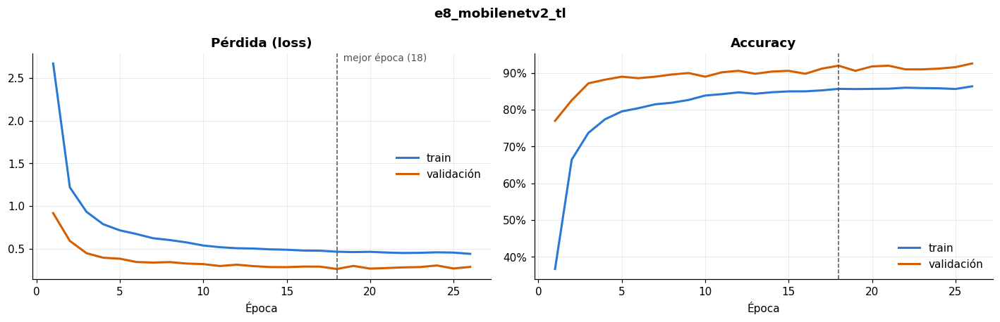

Mejor época (mínima val_loss): 18 -> val_loss = 0.262, val_accuracy = 92.0%
Máxima val_accuracy alcanzada: 92.6%
Última época: train accuracy = 86.4% | val accuracy = 92.6% | diferencia = -6.2 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %
e3_aug_dropout_gap,"479,908",80,11.4,76,1.412,60.0 %,52.6 %,-7.4 %
e4_aug_dropout_gap_bn,"481,828",55,17.6,45,1.583,54.4 %,47.1 %,-7.3 %
e5_aug_dropout025_gap,"479,908",86,12.8,76,1.127,71.6 %,67.4 %,-4.2 %
e6_5bloques,"1,725,604",48,8.0,38,1.191,70.4 %,70.4 %,0.0 %
cnn_final_scratch,"1,725,604",63,10.3,51,1.019,72.6 %,76.9 %,4.3 %
e7_resnet50v2_tl,"23,769,700",27,24.1,19,0.249,92.4 %,85.9 %,-6.5 %
e8_mobilenetv2_tl,"2,386,084",26,12.1,18,0.262,92.0 %,85.7 %,-6.3 %


In [ ]:
modelo_e8 = crear_modelo_tl("e8_mobilenetv2_tl", "mobilenetv2")
modelo_e8.summary()
h_e8 = entrenar_experimento_tl(modelo_e8, "e8_mobilenetv2_tl")
tabla_resultados()

**Resultados del experimento 8:**

Con MobileNetV2 alcanza prácticamente el mismo resultado que ResNet50V2: la accuracy de validación es de 92,0 % frente a 92,4 % y la val_loss mínima de 0,262 frente a 0,249.

Lo que si es que a diferencia de ResNet50V2 consigue con unas 10 veces menos parámetros y en la mitad de tiempo (12,1 minutos frente a 24,1), entrenando solo 128.100 parámetros del clasificador. La hipótesis de partida de que ResNet50V2 obtendría mayor accuracy no se confirma en esta fase.


## 4.2 Fine-tuning

A diferencia del transfer learning, el fine-tuning lo que hace es "descongelar" únicamente los valores de las últimas capas de la base y se entrenan estos valores junto con el clasificador, y así las características se adaptan a los deportes.

Algo importante a tener en cuenta es que el learning rate debe ser muy bajo (acá lo tomamos 100 veces menor al del transfer learning) porque solo se quieren ajustar pesos pequeños sobre pesos ya buenos.

Además, las capas de BatchNormalization se mantienen congeladas aunque estén dentro de la parte descongelada, para conservar las estadísticas de ImageNet; si se actualizaran con lotes pequeños de un dominio distinto, se desestabilizaría el modelo. Esto se hace en la función `preparar_fine_tuning`, que deja con `trainable = False` todas las capas de este tipo.

| Arquitectura | Capas descongeladas | Capas de la base |
|---|---|---|
| ResNet50V2 | desde `conv5_block1_preact_bn`: todo el último bloque convolucional (conv5) | 190 |
| MobileNetV2 | desde `block_13_expand`: los 4 últimos bloques invertidos (13 a 16) y la convolución final | 154 |

In [ ]:
def preparar_fine_tuning(nombre_origen, arquitectura):
    '''Carga el modelo de transfer learning guardado y descongela las últimas capas de su base.'''
    modelo = keras.models.load_model(str(RESULTS_DIR / f"{nombre_origen}.keras"))
    _, capa_inicio = ARQUITECTURAS[arquitectura]

    base = modelo.get_layer(arquitectura)
    base.trainable = True
    indice = [c.name for c in base.layers].index(capa_inicio)
    for capa in base.layers[:indice]:
        capa.trainable = False
    for capa in base.layers[indice:]:
        if isinstance(capa, layers.BatchNormalization):
            capa.trainable = False

    n_desc = sum(1 for c in base.layers[indice:] if c.trainable_weights)
    print(f"{arquitectura}: {len(base.layers) - indice} de {len(base.layers)} capas descongeladas "
          f"(desde '{capa_inicio}'), {n_desc} con pesos entrenables.")
    print(f"Parámetros entrenables: {int(sum(np.prod(w.shape) for w in modelo.trainable_weights)):,} de {modelo.count_params():,} "
          f"({100 * int(sum(np.prod(w.shape) for w in modelo.trainable_weights)) / modelo.count_params():.1f} %)")
    return modelo

### 4.2.1 ResNet50V2

resnet50v2: 36 de 190 capas descongeladas (desde 'conv5_block1_preact_bn'), 10 con pesos entrenables.
Parámetros entrenables: 15,155,300 de 23,769,700 (63.8 %)
Epoch 1/30
211/211 - 75s - 357ms/step - accuracy: 0.8825 - loss: 0.3761 - val_accuracy: 0.9300 - val_loss: 0.2153
Epoch 2/30
211/211 - 61s - 290ms/step - accuracy: 0.8971 - loss: 0.3278 - val_accuracy: 0.9380 - val_loss: 0.2212
Epoch 3/30
211/211 - 62s - 291ms/step - accuracy: 0.9023 - loss: 0.2968 - val_accuracy: 0.9360 - val_loss: 0.1915
Epoch 4/30
211/211 - 83s - 392ms/step - accuracy: 0.9135 - loss: 0.2658 - val_accuracy: 0.9420 - val_loss: 0.2049
Epoch 5/30
211/211 - 62s - 292ms/step - accuracy: 0.9202 - loss: 0.2422 - val_accuracy: 0.9340 - val_loss: 0.1829
Epoch 6/30
211/211 - 62s - 292ms/step - accuracy: 0.9294 - loss: 0.2237 - val_accuracy: 0.9400 - val_loss: 0.1892
Epoch 7/30
211/211 - 62s - 293ms/step - accuracy: 0.9334 - loss: 0.2029 - val_accuracy: 0.9420 - val_loss: 0.1813
Epoch 8/30
211/211 - 62s - 292ms/step - ac

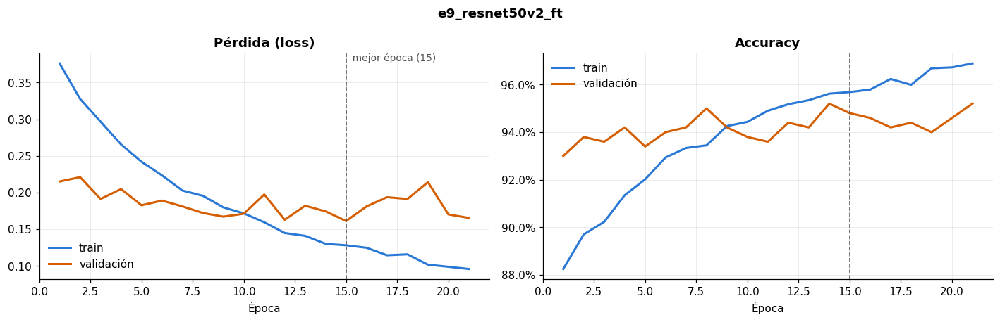

Mejor época (mínima val_loss): 15 -> val_loss = 0.161, val_accuracy = 94.8%
Máxima val_accuracy alcanzada: 95.2%
Última época: train accuracy = 96.9% | val accuracy = 95.2% | diferencia = 1.7 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %
e3_aug_dropout_gap,"479,908",80,11.4,76,1.412,60.0 %,52.6 %,-7.4 %
e4_aug_dropout_gap_bn,"481,828",55,17.6,45,1.583,54.4 %,47.1 %,-7.3 %
e5_aug_dropout025_gap,"479,908",86,12.8,76,1.127,71.6 %,67.4 %,-4.2 %
e6_5bloques,"1,725,604",48,8.0,38,1.191,70.4 %,70.4 %,0.0 %
cnn_final_scratch,"1,725,604",63,10.3,51,1.019,72.6 %,76.9 %,4.3 %
e7_resnet50v2_tl,"23,769,700",27,24.1,19,0.249,92.4 %,85.9 %,-6.5 %
e8_mobilenetv2_tl,"2,386,084",26,12.1,18,0.262,92.0 %,85.7 %,-6.3 %


In [ ]:
modelo_e9 = preparar_fine_tuning("e7_resnet50v2_tl", "resnet50v2")
h_e9 = entrenar_experimento_tl(modelo_e9, "e9_resnet50v2_ft", epochs=30, lr=1e-5, paciencia=6)
tabla_resultados()

**Resultados del experimento 9:**

- El fine-tuning de ResNet50V2 mejora el modelo ya que la accuracy de validación sube de 92,4 % a 94,8 % y la val_loss mínima baja de 0,249 a 0,161.
- La diferencia de la val_loss con respecto al transfer learning para ResNet50V2 (aproximadamente de un 35 %) indica que el modelo acierta con mayor confianza.
- Esta mejora se hizo entrenando unos 15,2 millones de parámetros (el último bloque de la base más el clasificador) en lugar de 205.000, y el coste es de 22,5 minutos adicionales a los 24,1 del experimento 7.
- Aparece una ligera diferencia entre entrenamiento y validación: en la mejor época la accuracy de entrenamiento (95,7 %) pasa a ser algo mayor que la de validación (94,8 %), con una brecha de solo 0,9 %, por lo que el sobreajuste es mínimo.

Este modelo es el mejor hasta ahora. A continuación se aplica el mismo procedimiento a MobileNetV2 para comprobar si, al adaptar su base, se acerca o supera a ResNet50V2.

### 4.2.2 MobileNetV2

mobilenetv2: 38 de 154 capas descongeladas (desde 'block_13_expand'), 13 con pesos entrenables.
Parámetros entrenables: 1,791,460 de 2,386,084 (75.1 %)
Epoch 1/30
211/211 - 40s - 188ms/step - accuracy: 0.8707 - loss: 0.4253 - val_accuracy: 0.9000 - val_loss: 0.2755
Epoch 2/30
211/211 - 29s - 138ms/step - accuracy: 0.8839 - loss: 0.3753 - val_accuracy: 0.9160 - val_loss: 0.2577
Epoch 3/30
211/211 - 29s - 137ms/step - accuracy: 0.8953 - loss: 0.3334 - val_accuracy: 0.9300 - val_loss: 0.2381
Epoch 4/30
211/211 - 42s - 197ms/step - accuracy: 0.8976 - loss: 0.3336 - val_accuracy: 0.9240 - val_loss: 0.2274
Epoch 5/30
211/211 - 41s - 192ms/step - accuracy: 0.8942 - loss: 0.3284 - val_accuracy: 0.9220 - val_loss: 0.2353
Epoch 6/30
211/211 - 28s - 135ms/step - accuracy: 0.9047 - loss: 0.3095 - val_accuracy: 0.9220 - val_loss: 0.2298
Epoch 7/30
211/211 - 29s - 137ms/step - accuracy: 0.9083 - loss: 0.2847 - val_accuracy: 0.9300 - val_loss: 0.2167
Epoch 8/30
211/211 - 29s - 138ms/step - accuracy: 

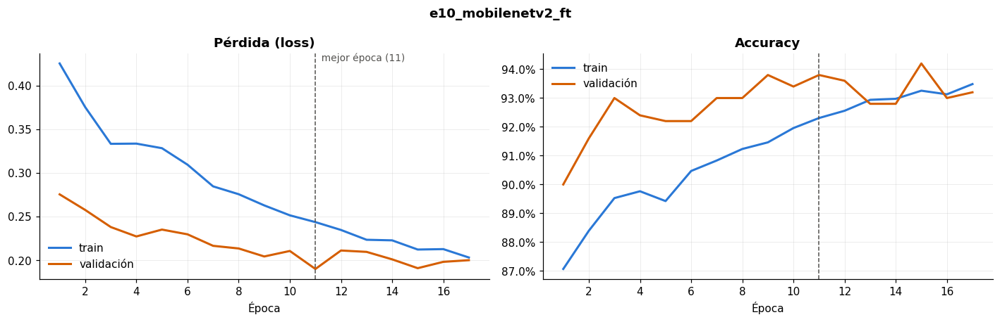

Mejor época (mínima val_loss): 11 -> val_loss = 0.190, val_accuracy = 93.8%
Máxima val_accuracy alcanzada: 94.2%
Última época: train accuracy = 93.5% | val accuracy = 93.2% | diferencia = 0.3 puntos


,parámetros,épocas,minutos,mejor época,val_loss mín,val_acc,train_acc,brecha
modelo_base,"4,608,676",30,3.7,4,2.254,40.8 %,47.8 %,7.0 %
e1_augmentation,"4,608,676",25,4.2,15,1.582,57.8 %,69.3 %,11.5 %
e2_aug_dropout,"4,608,676",76,11.3,66,1.174,67.4 %,60.9 %,-6.5 %
e3_aug_dropout_gap,"479,908",80,11.4,76,1.412,60.0 %,52.6 %,-7.4 %
e4_aug_dropout_gap_bn,"481,828",55,17.6,45,1.583,54.4 %,47.1 %,-7.3 %
e5_aug_dropout025_gap,"479,908",86,12.8,76,1.127,71.6 %,67.4 %,-4.2 %
e6_5bloques,"1,725,604",48,8.0,38,1.191,70.4 %,70.4 %,0.0 %
cnn_final_scratch,"1,725,604",63,10.3,51,1.019,72.6 %,76.9 %,4.3 %
e7_resnet50v2_tl,"23,769,700",27,24.1,19,0.249,92.4 %,85.9 %,-6.5 %
e8_mobilenetv2_tl,"2,386,084",26,12.1,18,0.262,92.0 %,85.7 %,-6.3 %


In [ ]:
modelo_e10 = preparar_fine_tuning("e8_mobilenetv2_tl", "mobilenetv2")
h_e10 = entrenar_experimento_tl(modelo_e10, "e10_mobilenetv2_ft", epochs=30, lr=1e-5, paciencia=6)
tabla_resultados()

**Resultados del experimento 10:**

El fine-tuning de MobileNetV2 también mejora el modelo con respecto al transfer learning: la accuracy de validación sube de 92,0 % a 93,8 % y la val_loss mínima baja de 0,262 a 0,190. Frente a ResNet50V2 con fine-tuning (94,8 %), la diferencia es de solo 1,0 punto y lo consigue con casi 10 veces menos parámetros y en menos de la mitad de tiempo (9,2 minutos frente a 22,5), entrenando unos 1,8 millones de parámetros. Además, acá tampoco hay sobreajuste.

**Decisión:** las dos arquitecturas quedan muy igualadas, así que MobileNetV2 con fine-tuning ofrece la mejor relación entre rendimiento y coste, mientras que ResNet50V2 con fine-tuning obtiene el mejor resultado absoluto por una diferencia pequeña. Se comparan todos los modelos en la siguiente sección.

# 5. Comparación de todos los modelos

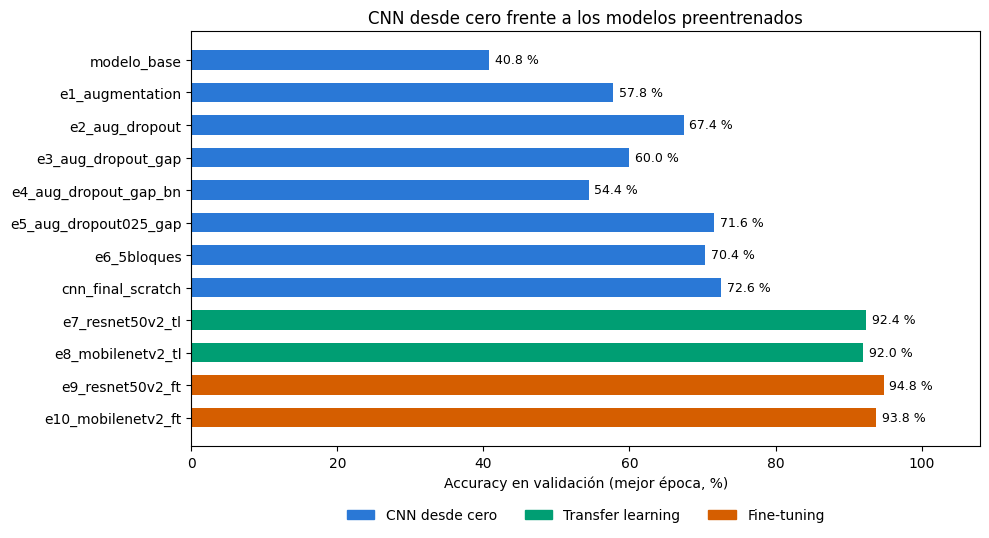

In [ ]:
from matplotlib.patches import Patch

COLOR_TL = "#009e73"   # transfer learning (COLOR: desde cero, COLOR_VAL: fine-tuning)

def color_de(nombre):
    if nombre.endswith("_tl"):
        return COLOR_TL
    if nombre.endswith("_ft"):
        return COLOR_VAL
    return COLOR

# nombres = list(RESULTADOS.keys())
# val_accs = [100 * RESULTADOS[n]["val_acc"] for n in nombres]

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.barh(nombres, val_accs, color=[color_de(n) for n in nombres], height=0.6)
ax.invert_yaxis()
for barra, v in zip(barras, val_accs):
    ax.text(v + 0.8, barra.get_y() + barra.get_height() / 2, f"{v:.1f} %", va="center", fontsize=9)
ax.set_xlim(0, 108)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Accuracy en validación (mejor época, %)")
ax.set_title("CNN desde cero frente a los modelos preentrenados")
ax.legend(handles=[Patch(color=COLOR, label="CNN desde cero"),
                   Patch(color=COLOR_TL, label="Transfer learning"),
                   Patch(color=COLOR_VAL, label="Fine-tuning")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 5.1 Evaluación en test

Hasta ahora todas las decisiones se tomaron con el conjunto de validación. Para comparar las estrategias de forma justa, se evalúan en el conjunto de test (que no se usó en ninguna decisión) los dos modelos finales de la estrategia 2, cada uno con los pesos de su mejor época guardados en la carpeta de resultados. El resultado de la CNN desde cero se lee del archivo guardado en la sección 3.11.

La primera celda prepara el conjunto de test a 128×128 y a 224×224 igual que en la sección 2.2 (sin barajar), sin depender de las celdas de entrenamiento.

In [ ]:

import json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

CLASES = sorted(p.name for p in SPLITS["test"].iterdir() if p.is_dir())

def cargar_test(img_size):
    ds = keras.utils.image_dataset_from_directory(
        SPLITS["test"], labels="inferred", label_mode="int", class_names=CLASES,
        color_mode="rgb", image_size=(img_size, img_size), interpolation="area",
        batch_size=64, shuffle=False)
    return ds.map(lambda x, y: (tf.round(x), y))

test_128 = cargar_test(128)
test_224 = cargar_test(224)

Found 500 files belonging to 100 classes.
Found 500 files belonging to 100 classes.


In [ ]:

n_test = int(sum(int(y.shape[0]) for _, y in test_224))

TEST = {}
with open(RESULTS_DIR / "test_cnn_scratch.json") as f:
    s = json.load(f)
TEST["cnn_final_scratch"] = {"test_acc": s["test_acc"], "test_loss": s["test_loss"], "ic95": s["ic95"]}

for nombre in ["e9_resnet50v2_ft", "e10_mobilenetv2_ft"]:
    modelo = keras.models.load_model(str(RESULTS_DIR / f"{nombre}.keras"), compile=False)
    modelo.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    loss, acc = modelo.evaluate(test_224, verbose=0)
    margen = 1.96 * np.sqrt(acc * (1 - acc) / n_test)
    TEST[nombre] = {"test_acc": float(acc), "test_loss": float(loss), "ic95": float(margen)}

for nombre, t in TEST.items():
    print(f"{nombre:<20} accuracy en test = {t['test_acc']:.1%}  "
          f"(IC 95 %: {t['test_acc'] - t['ic95']:.1%} a {t['test_acc'] + t['ic95']:.1%}) | loss = {t['test_loss']:.3f}")

with open(RESULTS_DIR / "test_todos.json", "w") as f:
    json.dump(TEST, f, indent=2)

cnn_final_scratch    accuracy en test = 74.2%  (IC 95 %: 70.4% a 78.0%) | loss = 0.945
e9_resnet50v2_ft     accuracy en test = 96.6%  (IC 95 %: 95.0% a 98.2%) | loss = 0.124
e10_mobilenetv2_ft   accuracy en test = 95.4%  (IC 95 %: 93.6% a 97.2%) | loss = 0.142


## 5.2 Tabla comparativa final

In [ ]:
def mejor_epoca(nombre):
    with open(RESULTS_DIR / f"historial_{nombre}.json") as f:
        h = json.load(f)
    i = int(np.argmin(h["val_loss"]))
    return h["val_accuracy"][i], i + 1

TIEMPOS = {"cnn_final_scratch": 10.3, "e7_resnet50v2_tl": 24.1, "e8_mobilenetv2_tl": 12.1,
           "e9_resnet50v2_ft": 22.5, "e10_mobilenetv2_ft": 9.2}

MODELOS = [
    ("CNN desde cero", "cnn_final_scratch", None, "128×128"),
    ("ResNet50V2 (transfer learning + fine-tuning)", "e9_resnet50v2_ft", "e7_resnet50v2_tl", "224×224"),
    ("MobileNetV2 (transfer learning + fine-tuning)", "e10_mobilenetv2_ft", "e8_mobilenetv2_tl", "224×224"),
]

filas = []
for etiqueta, final, previo, resolucion in MODELOS:
    modelo = keras.models.load_model(str(RESULTS_DIR / f"{final}.keras"), compile=False)
    entrenables = int(sum(np.prod(w.shape) for w in modelo.trainable_weights))
    val_acc, _ = mejor_epoca(final)
    t = TEST[final]
    filas.append({
        "Modelo": etiqueta,
        "Accuracy test": f"{100 * t['test_acc']:.1f} %",
        "IC 95 %": f"± {100 * t['ic95']:.1f}",
        "Loss test": round(t["test_loss"], 3),
        "Accuracy validación": f"{100 * val_acc:.1f} %",
        "Parámetros totales": f"{modelo.count_params():,}",
        "Parámetros entrenados": f"{entrenables:,}",
        "Tiempo total (min)": round(TIEMPOS[final] + (TIEMPOS[previo] if previo else 0), 1),
        "Resolución": resolucion,
    })

display(pd.DataFrame(filas).set_index("Modelo"))

,Accuracy test,IC 95 %,Loss test,Accuracy validación,Parámetros totales,Parámetros entrenados,Tiempo total (min),Resolución
Modelo,,,,,,,,
CNN desde cero,74.2 %,± 3.8,0.945,72.6 %,"1,725,604","1,725,604",10.3,128×128
ResNet50V2 (transfer learning + fine-tuning),96.6 %,± 1.6,0.124,94.8 %,"23,769,700","15,155,300",46.6,224×224
MobileNetV2 (transfer learning + fine-tuning),95.4 %,± 1.8,0.142,93.8 %,"2,386,084","1,791,460",21.3,224×224


## 5.3 Análisis de errores

In [ ]:
def errores_frecuentes(nombre, ds, top=8):
    modelo = keras.models.load_model(str(RESULTS_DIR / f"{nombre}.keras"), compile=False)
    y_true = np.concatenate([y.numpy() for _, y in ds])
    y_pred = np.argmax(modelo.predict(ds, verbose=0), axis=1)
    errores = pd.Series([f"{CLASES[t]}  →  {CLASES[p]}" for t, p in zip(y_true, y_pred) if t != p])
    print(f"{nombre}: {len(errores)} errores de {len(y_true)} imágenes de test "
          f"(accuracy = {1 - len(errores) / len(y_true):.1%})")
    display(errores.value_counts().head(top).rename("nº de veces").to_frame())

errores_frecuentes("cnn_final_scratch", test_128)
errores_frecuentes("e9_resnet50v2_ft", test_224)

cnn_final_scratch: 129 errores de 500 imágenes de test (accuracy = 74.2%)


,nº de veces
bmx → skydiving,2
formula 1 racing → nascar racing,2
snow boarding → giant slalom,2
archery → rings,1
balance beam → uneven bars,1
axe throwing → archery,1
barell racing → disc golf,1
barell racing → steer wrestling,1


e9_resnet50v2_ft: 17 errores de 500 imágenes de test (accuracy = 96.6%)


,nº de veces
bmx → motorcycle racing,1
bmx → bike polo,1
bowling → jai alai,1
figure skating men → figure skating women,1
football → lacrosse,1
frisbee → figure skating women,1
hydroplane racing → bobsled,1
lacrosse → cricket,1


**Análisis de errores:**

- La CNN desde cero comete 129 errores en las 500 imágenes de test, mientras que ResNet50V2 con fine-tuning solo comete 17 (un 87 % menos). La accuracy calculada aquí para la CNN desde cero (74,2 %) coincide con la de la sección 3.11, lo que confirma que se están evaluando los mismos modelos.
- En la CNN desde cero, las confusiones que se repiten son entre deportes con un contexto visual muy parecido: formula 1 racing con nascar racing (una de las parejas que se anticiparon en la sección 1.1), snow boarding con giant slalom (pistas de nieve) y balance beam con uneven bars (gimnasia). También aparecen errores menos lógicos, como bmx confundido con skydiving o barell racing con disc golf, lo que indica que este modelo se apoya mucho en el fondo y los colores de la escena más que en los objetos.
- En ResNet50V2 ningún error se repite, y la mayoría ocurre entre deportes relacionados: bmx con motorcycle racing y bike polo (bicicletas y motos), figure skating men con figure skating women, football con lacrosse (cascos y protecciones) o hydroplane racing con bobsled (vehículos de velocidad). Es decir, incluso cuando se equivoca, el modelo preentrenado suele elegir un deporte parecido.

# 6. Conclusiones finales

## 6.1 Rendimiento en test

Como se puede observar en la tabla de la sección 5.2, la estrategia de transfer learning con fine-tuning supera ampliamente a la CNN desde cero: ResNet50V2 obtiene un **96,6 %** de accuracy en test (IC 95 %: 95,0 % a 98,2 %) y MobileNetV2 un **95,4 %** (IC 95 %: 93,6 % a 97,2 %), frente al **74,2 %** de la CNN desde cero (IC 95 %: 70,4 % a 78,0 %). La diferencia, de más de 21 puntos, es mucho mayor que los márgenes de error y los intervalos no se solapan, por lo que se trata de una diferencia real y no de un efecto del azar. En número de errores, la CNN desde cero falla 129 de las 500 imágenes de test y ResNet50V2 solo 17.

En los tres modelos la accuracy de test es muy parecida a la de validación, e incluso algo superior (74,2 % frente a 72,6 %; 96,6 % frente a 94,8 %; 95,4 % frente a 93,8 %), lo que confirma que las decisiones tomadas con el conjunto de validación no hicieron que los modelos se ajustaran a esas imágenes en particular.

## 6.2 Evolución del entrenamiento

La diferencia más llamativa entre las dos estrategias está en la velocidad de aprendizaje. La CNN desde cero necesitó 51 épocas para llegar a su mejor resultado (72,6 % en validación), mientras que ResNet50V2 con la base congelada alcanzó un 82,4 % ya en la primera época, y MobileNetV2 un 77,0 %. Es decir, con una sola época de entrenamiento del clasificador, los modelos preentrenados ya superan al mejor modelo desde cero.

Esto se debe a que las características aprendidas en ImageNet (bordes, texturas, personas, balones, bicicletas, coches, agua, césped…) sirven directamente para reconocer deportes, mientras que la CNN desde cero tiene que aprender todo a partir de unas 135 imágenes por clase. El fine-tuning aportó después una mejora adicional moderada (de 92,4 % a 94,8 % en ResNet50V2 y de 92,0 % a 93,8 % en MobileNetV2) y, sobre todo, redujo la val_loss entre un 27 % y un 35 %, lo que indica que los modelos aciertan con más seguridad.


## 6.3 Generalización, sobreajuste y subajuste

- **CNN desde cero:** el principal problema fue el sobreajuste. El data augmentation y el dropout lo controlaron, pero un exceso de regularización (dropout 0,5 junto con GlobalAveragePooling, o la Batch Normalization) llevó al extremo contrario: el modelo no superaba el 53 % de accuracy en entrenamiento (subajuste). Ajustando el dropout se llegó al equilibrio, con una brecha de 4,3 puntos en la mejor época del modelo final. Aun así, el análisis de errores muestra que este modelo se apoya mucho en el contexto de la escena, lo que limita su capacidad de generalización.
- **Transfer learning (base congelada):** no aparece sobreajuste. La accuracy de entrenamiento queda por debajo de la de validación (−6,5 y −6,3 puntos), porque en entrenamiento se aplican data augmentation y dropout, y solo se entrenan entre 128.000 y 205.000 parámetros.
- **Fine-tuning:** al descongelar parte de la base el modelo entrena muchos más parámetros (15,2 millones en ResNet50V2 y 1,8 millones en MobileNetV2), y en ResNet50V2 aparece una brecha pequeña (0,9 puntos en la mejor época). Se mantuvo controlada gracias a un learning rate 100 veces menor (0,00001), al early stopping y a mantener congeladas las capas de Batch Normalization, una decisión apoyada también en lo observado en el experimento 4. El resultado en test (96,6 %) confirma que el modelo generaliza bien.

## 6.4 Ventajas e inconvenientes de cada estrategia

| Aspecto | CNN desde cero | Transfer learning + fine-tuning |
|---|---|---|
| Accuracy en test | 74,2 % | 95,4 % (MobileNetV2), 96,6 % (ResNet50V2) |
| Errores en test (de 500) | 129 | 17 (ResNet50V2) |
| Épocas hasta el mejor resultado | 51 | 18 + 11 (MobileNetV2), 19 + 15 (ResNet50V2) |
| Tiempo por época | unos 9 s (128×128) | entre 25 y 62 s (224×224) |
| Tiempo total de entrenamiento | 10,3 min | 21,3 min (MobileNetV2), 46,6 min (ResNet50V2) |
| Parámetros del modelo | 1,7 millones | 2,4 millones (MobileNetV2), 23,8 millones (ResNet50V2) |
| Experimentos necesarios | 8 | 2 por arquitectura |


- **CNN desde cero.** Ventajas: modelo pequeño y rápido por época, control total de la arquitectura y no depende de pesos externos. Inconvenientes: con pocas imágenes por clase su rendimiento es claramente inferior, necesita muchas épocas y muchos experimentos de ajuste, es muy sensible a la elección de las técnicas de regularización y se apoya demasiado en el fondo de la imagen.
- **Transfer learning + fine-tuning.** Ventajas: rendimiento muy superior, buenos resultados desde las primeras épocas, muchos menos experimentos de ajuste y errores más "razonables" (entre deportes parecidos). Inconvenientes: modelos más grandes y más lentos por época, necesitan imágenes de 224×224 (más memoria) y dependen de que el dominio se parezca al de ImageNet. Además, el fine-tuning exige cuidado (learning rate bajo, Batch Normalization congelada) para no destruir lo aprendido.

## 6.5 Elección final

Para este problema, **la mejor estrategia es el transfer learning con fine-tuning**: con pocas imágenes por clase y 100 categorías, aprovechar las características aprendidas en ImageNet supone una ventaja de más de 21 puntos de accuracy en test que la CNN desde cero no consiguió alcanzar a pesar de las técnicas de regularización.

Entre las dos arquitecturas, **ResNet50V2 con fine-tuning obtiene el mejor resultado** (96,6 % en test, con una loss de 0,124). Sin embargo, la diferencia con MobileNetV2 (95,4 %) es de solo 1,2 puntos, sus intervalos de confianza se solapan, y MobileNetV2 tiene 10 veces menos parámetros y se entrena en menos de la mitad de tiempo. Por eso, si el criterio es la máxima accuracy, el modelo elegido es ResNet50V2; pero si también se tiene en cuenta el coste (por ejemplo, para usarlo en un móvil o con pocos recursos), **MobileNetV2 con fine-tuning ofrece prácticamente el mismo rendimiento con un coste mucho menor**.


## 6.6 Limitaciones

- La comparación no es del todo equitativa: la CNN desde cero trabajó a 128×128 y los modelos preentrenados a 224×224, por lo que parte de la diferencia puede deberse a la resolución. Aun así, que los modelos preentrenados superen al mejor modelo desde cero en su primera época indica que el factor principal son las características aprendidas en ImageNet.
- Cada experimento se entrenó una sola vez y los conjuntos de validación y test tienen 500 imágenes, por lo que las diferencias menores de 2-4 puntos no son concluyentes.
- No se experimentó con regularización L2, ya que el sobreajuste quedó controlado con data augmentation y dropout.